# Имопртирование библиотек

In [2]:
!conda list > requirements.txt
# !conda uninstall pytorch torchvision torchaudio
# !conda install -y pytorch torchvision torchaudio -c pytorch-nightly
# !conda install -y xgboost sdv boto3
# !pip install feature-engine torch==2.5.0 pgmpy

In [3]:
import pandas as pd
import numpy as np
import math

import seaborn as sns
import matplotlib.pyplot as plt

import lightgbm as lgb
import networkx as nx
from feature_engine import encoding as ce

from sklearn.metrics import f1_score, fbeta_score, roc_auc_score, roc_curve, auc, confusion_matrix, precision_score, accuracy_score, recall_score, mean_squared_error, mean_absolute_percentage_error, mean_absolute_error
from sklearn.model_selection import train_test_split, GridSearchCV, RepeatedStratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.datasets import load_breast_cancer
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

import xgboost as xgb

import torch

from sdv.single_table import CTGANSynthesizer
from sdv.datasets.demo import get_available_demos, download_demo
from sdv.evaluation.single_table import run_diagnostic
from sdv.metadata import SingleTableMetadata

# import sys
# sys.path.append('./BAMT')

# import bamt.preprocessors as pp
# import bamt.networks as nets

from pgmpy.models import BayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator, HillClimbSearch, BicScore
from pgmpy.estimators import K2Score, BDsScore
from pgmpy.sampling import BayesianModelSampling

%matplotlib inline

import warnings
warnings.simplefilter('ignore')

In [4]:
# Load the Drive helper and mount
# from google.colab import drive
# drive.mount('/content/drive')

In [5]:
CTGAN_COLOR = '#FF00FF'
BAMT_COLOR = '#1E90FF'
REAL_COLOR = '#006400'

In [6]:
def lgbm_predict(xx_train, yy_train, xx_test, yy_test, categorical_features, reg=False):
    for col in categorical_features:
        xx_train[col] = xx_train[col].astype('category')
        xx_test[col] = xx_test[col].astype('category')
    if not reg:
        model = lgb.LGBMClassifier(random_state=42, categorical_feature=categorical_features)
        model.fit(xx_train, yy_train)
        y_pred_test = model.predict_proba(xx_test)[:, 1]
    else:
        model = lgb.LGBMRegressor(random_state=42, categorical_feature=categorical_features)
        model.fit(xx_train, yy_train)
        y_pred_test = model.predict(xx_test)
    return y_pred_test

def xgb_predict(xx_train, yy_train, xx_test, yy_test, categorical_features):
    for col in categorical_features:
        xx_train[col] = xx_train[col].astype('category')
        xx_test[col] = xx_test[col].astype('category')

    dtrain = xgb.DMatrix(xx_train, label=yy_train, enable_categorical=True)
    dtest = xgb.DMatrix(xx_test, enable_categorical=True)

    params = {
        'objective': 'reg:squarederror',
        'random_state': 42,
    }

    model = xgb.train(params, dtrain)
    y_pred_test = model.predict(dtest)

    return y_pred_test

def fit_predict(clf, xx_train, yy_train, xx_test, yy_test, reg=False):
    clf.fit(xx_train,yy_train)
    if not reg:
        y_pred_test = clf.predict_proba(xx_test)[:, 1]
    else:
        y_pred_test = clf.predict(xx_test)
    return y_pred_test

In [7]:
def remove_outliers(df, exclude_l=[]):
    # Только для числовых столбцов
    numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns
    if len(exclude_l):
        numeric_columns = numeric_columns.drop(exclude_l)
    print(numeric_columns)
    
    # Для каждого столбца вычисляем Q1 (25-й процентиль) и Q3 (75-й процентиль)
    Q1 = df[numeric_columns].quantile(0.25)
    Q3 = df[numeric_columns].quantile(0.75)
    
    # Вычисляем межквартильный размах (IQR)
    IQR = Q3 - Q1
    
    # Определяем границы для удаления выбросов
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Фильтруем выбросы
    df_cleaned = df[~((df[numeric_columns] < lower_bound) | (df[numeric_columns] > upper_bound)).any(axis=1)]
    
    return df_cleaned

In [8]:
color_list = [REAL_COLOR, CTGAN_COLOR, BAMT_COLOR, "red", "black", "purple"]
def plot_roc_curve(y_all):
    fig = plt.figure(figsize=(12, 8))
    lw = 2

    for i, y_label in enumerate(y_all):
        y_true, y_pred = np.array(y_all[y_label][0]), np.array(y_all[y_label][1])

        [fpr, tpr, tresholds] = roc_curve(y_true, y_pred)
        metric_value = auc(fpr, tpr)
        plt.plot(
            fpr,
            tpr,
            color=color_list[i],
            lw=lw,
            label=f"AUC {y_label} {round(metric_value, 3)}",
        )

    plt.plot([0, 1], [0, 1], color="navy", lw=lw, linestyle="--")
    plt.title("Roc curve", fontsize=18)
    plt.xlabel("False Positive Rate", fontsize=18)
    plt.ylabel("True Positive Rate", fontsize=18)
    plt.grid(color="gray", linestyle="--", linewidth=0.5)
    plt.legend(loc="lower right", fontsize=14)
    plt.show()

# Загрузка данных для задачи классификации

In [10]:
data = pd.read_csv('./data/BankChurners.csv')

churn_map = {'Existing Customer': 0,
            'Attrited Customer': 1}

data['target'] = data['Attrition_Flag'].map(churn_map)

data.drop('Attrition_Flag', axis=1, inplace=True)

In [11]:
data.drop(['CLIENTNUM',
        'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
     'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'],
        axis=1, inplace=True)

data[data.columns[15:16]] = data[data.columns[15:16]].astype(float)

data.head()

,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,target
0,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144.0,42,1.625,0.061,0
1,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291.0,33,3.714,0.105,0
2,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887.0,20,2.333,0.000,0
3,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171.0,20,2.333,0.760,0
4,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816.0,28,2.500,0.000,0


In [12]:
data.shape

(10127, 20)

In [13]:
data.dtypes.value_counts()

int64      9
float64    6
object     5
Name: count, dtype: int64

In [14]:
data = data[['Gender', 'Dependent_count', 'Marital_Status', 'Income_Category', 'Card_Category', 
             'Total_Relationship_Count', 'Credit_Limit', 'Avg_Open_To_Buy', 'Total_Trans_Amt', 
             'Total_Trans_Ct', 'Customer_Age', 'Months_on_book', 
             'Total_Amt_Chng_Q4_Q1', 'target']]

In [15]:
X_train, X_test, y_train, y_test = train_test_split(data.drop(['target'], axis=1),
                                                    data['target'], test_size=0.1,
                                                    shuffle=True, stratify=data['target'],
                                                    random_state=42)

In [16]:
X_train.shape, X_test.shape,

((9114, 13), (1013, 13))

In [17]:
y_train.mean(), y_test.mean()

(0.16063199473337722, 0.16090819348469892)

In [18]:
real_data = X_train.copy()
real_data['target'] = y_train
categorical_features = list(real_data.loc[:, real_data.dtypes == object].columns)

print(categorical_features)

['Gender', 'Marital_Status', 'Income_Category', 'Card_Category']


In [19]:
for col in categorical_features:
    print(col, '-', real_data[col].nunique())

Gender - 2
Marital_Status - 4
Income_Category - 6
Card_Category - 4


In [20]:
real_data.dtypes.value_counts()

int64      6
object     4
float64    4
Name: count, dtype: int64

In [278]:
from diffprivlib.models import GaussianNB

clf = GaussianNB(epsilon=0.1)
clf.fit(X_train, y_train)

ValueError: could not convert string to float: 'Unknown'

# Генерация синтетических данных при помощи CTGAN для задачи классификации

In [22]:
metadata = SingleTableMetadata()
metadata.detect_from_dataframe(real_data)
python_dict = metadata.to_dict()

INFO:sdv.metadata.single_table:Detected metadata:
INFO:sdv.metadata.single_table:{
    "METADATA_SPEC_VERSION": "SINGLE_TABLE_V1",
    "columns": {
        "Gender": {
            "sdtype": "categorical"
        },
        "Dependent_count": {
            "sdtype": "categorical"
        },
        "Marital_Status": {
            "sdtype": "categorical"
        },
        "Income_Category": {
            "sdtype": "categorical"
        },
        "Card_Category": {
            "sdtype": "categorical"
        },
        "Total_Relationship_Count": {
            "sdtype": "categorical"
        },
        "Credit_Limit": {
            "sdtype": "numerical"
        },
        "Avg_Open_To_Buy": {
            "sdtype": "numerical"
        },
        "Total_Trans_Amt": {
            "sdtype": "numerical"
        },
        "Total_Trans_Ct": {
            "sdtype": "numerical"
        },
        "Customer_Age": {
            "sdtype": "numerical"
        },
        "Months_on_book": {
        

In [23]:
metadata.save_to_json('./data/metadata_cls.json')

ValueError: A file named 'metadata_cls.json' already exists in this folder. Please specify a different filename.

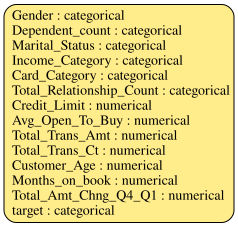

In [63]:
metadata.visualize()

In [65]:
%%time
ctgan_model = CTGANSynthesizer(
    metadata,
    enforce_rounding=True,
    epochs=300,
    verbose=True,
    enforce_min_max_values=True
)
ctgan_model.fit(real_data)

synthetic_data = ctgan_model.sample(num_rows=real_data.shape[0])
synthetic_data.head()

INFO:SingleTableSynthesizer:{'EVENT': 'Instance', 'TIMESTAMP': datetime.datetime(2025, 3, 8, 12, 14, 40, 62522), 'SYNTHESIZER CLASS NAME': 'CTGANSynthesizer', 'SYNTHESIZER ID': 'CTGANSynthesizer_1.18.0_ed4a7e138d204985ac17e669817d8005'}
INFO:SingleTableSynthesizer:{'EVENT': 'Fit', 'TIMESTAMP': datetime.datetime(2025, 3, 8, 12, 14, 40, 63182), 'SYNTHESIZER CLASS NAME': 'CTGANSynthesizer', 'SYNTHESIZER ID': 'CTGANSynthesizer_1.18.0_ed4a7e138d204985ac17e669817d8005', 'TOTAL NUMBER OF TABLES': 1, 'TOTAL NUMBER OF ROWS': 9114, 'TOTAL NUMBER OF COLUMNS': 14}
INFO:sdv.data_processing.data_processor:Fitting table  metadata
INFO:sdv.data_processing.data_processor:Fitting formatters for table 
INFO:sdv.data_processing.data_processor:Fitting constraints for table 
INFO:sdv.data_processing.data_processor:Setting the configuration for the ``HyperTransformer`` for table 
INFO:sdv.data_processing.data_processor:Fitting HyperTransformer for table 
INFO:SingleTableSynthesizer:{'EVENT': 'Fit processed d

CPU times: user 5min 52s, sys: 28.9 s, total: 6min 21s
Wall time: 1min 20s


,Gender,Dependent_count,Marital_Status,Income_Category,Card_Category,Total_Relationship_Count,Credit_Limit,Avg_Open_To_Buy,Total_Trans_Amt,Total_Trans_Ct,Customer_Age,Months_on_book,Total_Amt_Chng_Q4_Q1,target
0,M,2,Divorced,Unknown,Platinum,1,34516.0,34296.0,15405.0,71,44,36,0.881,1
1,F,3,Single,Less than $40K,Blue,5,10226.5,2106.7,1763.0,33,34,45,0.639,0
2,F,2,Single,Less than $40K,Blue,2,2081.2,830.7,2498.0,41,43,38,0.562,0
3,M,3,Single,$80K - $120K,Blue,3,2473.4,139.3,1608.0,36,49,53,1.154,0
4,M,0,Single,$60K - $80K,Blue,3,17268.8,4857.8,859.0,29,42,42,0.689,0


In [67]:
synthetic_data.shape

(9114, 14)

In [69]:
synthetic_data.to_csv('./synthetic data/synthetic_data_CTGAN_cls.csv', index=False)

# Генерация синтетических данных при помощи Байесовских сетей для задачи классификации

In [71]:
label_encoders = {}
real_data_enc = real_data.copy()

for column in real_data_enc.select_dtypes(include=['object', 'category']).columns:
    le = LabelEncoder()
    real_data_enc[column] = le.fit_transform(real_data_enc[column])
    label_encoders[column] = le

real_data_enc = real_data_enc.dropna()
real_data_enc

,Gender,Dependent_count,Marital_Status,Income_Category,Card_Category,Total_Relationship_Count,Credit_Limit,Avg_Open_To_Buy,Total_Trans_Amt,Total_Trans_Ct,Customer_Age,Months_on_book,Total_Amt_Chng_Q4_Q1,target
3346,1,4,1,2,0,3,22956.0,21549.0,5554.0,64,40,36,0.709,0
5204,1,1,2,2,0,3,19090.0,19090.0,4712.0,88,57,43,0.530,0
7675,0,2,1,1,0,5,2653.0,2653.0,5052.0,81,55,36,0.969,0
1021,1,3,1,3,3,6,34516.0,34516.0,1733.0,54,48,36,0.691,0
6508,0,2,1,4,0,5,1978.0,1978.0,4870.0,83,56,43,0.641,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2391,1,4,2,2,0,5,12280.0,11295.0,4263.0,70,46,40,0.841,0
3809,0,5,1,4,0,5,2950.0,950.0,4742.0,79,47,40,0.882,0
9889,0,3,2,1,3,2,19713.0,19182.0,8301.0,70,43,36,0.792,1
7915,0,0,0,4,0,6,1732.0,1732.0,2479.0,43,32,36,0.683,1


In [73]:
cleaned_real_data = remove_outliers(real_data_enc, exclude_l=['target', 'Card_Category'])

print(f"Размер данных до очистки: {real_data_enc.shape}")
print(f"Размер данных после очистки: {cleaned_real_data.shape}")

Index(['Gender', 'Dependent_count', 'Marital_Status', 'Income_Category',
       'Total_Relationship_Count', 'Credit_Limit', 'Avg_Open_To_Buy',
       'Total_Trans_Amt', 'Total_Trans_Ct', 'Customer_Age', 'Months_on_book',
       'Total_Amt_Chng_Q4_Q1'],
      dtype='object')
Размер данных до очистки: (9114, 14)
Размер данных после очистки: (6875, 14)


In [75]:
# Выбираем непрерывные переменные
continuous_columns = cleaned_real_data.select_dtypes(include=['float64', 'int64']).columns
# Дискретизация с использованием равных интервалов (по умолчанию — 5 интервалов)
discretizer = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform')
# Применяем дискретизацию к непрерывным переменным
cleaned_real_data[continuous_columns] = discretizer.fit_transform(cleaned_real_data[continuous_columns])

In [77]:
hc = HillClimbSearch(cleaned_real_data)
# best_model = hc.estimate(scoring_method=BicScore(real_data))
best_model = hc.estimate(scoring_method=BDsScore(cleaned_real_data)) #  K2Score

model = BayesianNetwork(best_model.edges())
model.fit(real_data_enc, estimator=MaximumLikelihoodEstimator)


  0%|          | 0/1000000 [00:00<?, ?it/s]

In [79]:
#Генерация новых синтетических данных
sampler = BayesianModelSampling(model)

synthetic_samples = sampler.forward_sample(size=real_data_enc.shape[0])

synthetic_samples_df = pd.DataFrame(synthetic_samples)

synthetic_samples_df

  0%|          | 0/14 [00:00<?, ?it/s]

,Gender,Total_Trans_Amt,target,Marital_Status,Customer_Age,Income_Category,Card_Category,Credit_Limit,Avg_Open_To_Buy,Total_Trans_Ct,Total_Relationship_Count,Total_Amt_Chng_Q4_Q1,Months_on_book,Dependent_count
0,0,14334.0,0,1,32,4,0,6572.0,1676.0,97,1,0.796,16,1
1,1,2508.0,1,1,43,3,0,26792.0,24956.0,71,1,0.643,31,4
2,0,3987.0,0,1,44,1,0,21046.0,5145.0,29,6,0.202,29,1
3,0,4560.0,0,1,53,4,0,3083.0,2043.0,84,6,0.945,19,0
4,1,1164.0,0,1,54,2,0,5070.0,5070.0,43,3,0.766,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9109,0,4590.0,0,2,36,4,0,2490.0,867.0,88,3,0.806,31,2
9110,0,4665.0,0,2,53,4,0,1844.0,612.0,67,3,0.737,36,0
9111,0,4518.0,0,1,40,5,0,2765.0,2765.0,79,5,0.573,36,4
9112,1,3503.0,0,0,53,0,3,34516.0,33470.0,66,4,0.971,14,0


In [81]:
synthetic_samples_df.shape

(9114, 14)

In [83]:
cleared_synthetic_samples_df = remove_outliers(synthetic_samples_df)
cleared_synthetic_samples_df.shape

Index(['Gender', 'Total_Trans_Amt', 'target', 'Marital_Status', 'Customer_Age',
       'Income_Category', 'Card_Category', 'Credit_Limit', 'Avg_Open_To_Buy',
       'Total_Trans_Ct', 'Total_Relationship_Count', 'Total_Amt_Chng_Q4_Q1',
       'Months_on_book', 'Dependent_count'],
      dtype='object')


(5304, 14)

In [85]:
# Декодируем обратно категориальные переменные
for column, le in label_encoders.items():
    synthetic_samples_df[column] = le.inverse_transform(synthetic_samples_df[column])

synthetic_samples_df

,Gender,Total_Trans_Amt,target,Marital_Status,Customer_Age,Income_Category,Card_Category,Credit_Limit,Avg_Open_To_Buy,Total_Trans_Ct,Total_Relationship_Count,Total_Amt_Chng_Q4_Q1,Months_on_book,Dependent_count
0,F,14334.0,0,Married,32,Less than $40K,Blue,6572.0,1676.0,97,1,0.796,16,1
1,M,2508.0,1,Married,43,$80K - $120K,Blue,26792.0,24956.0,71,1,0.643,31,4
2,F,3987.0,0,Married,44,$40K - $60K,Blue,21046.0,5145.0,29,6,0.202,29,1
3,F,4560.0,0,Married,53,Less than $40K,Blue,3083.0,2043.0,84,6,0.945,19,0
4,M,1164.0,0,Married,54,$60K - $80K,Blue,5070.0,5070.0,43,3,0.766,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9109,F,4590.0,0,Single,36,Less than $40K,Blue,2490.0,867.0,88,3,0.806,31,2
9110,F,4665.0,0,Single,53,Less than $40K,Blue,1844.0,612.0,67,3,0.737,36,0
9111,F,4518.0,0,Married,40,Unknown,Blue,2765.0,2765.0,79,5,0.573,36,4
9112,M,3503.0,0,Divorced,53,$120K +,Silver,34516.0,33470.0,66,4,0.971,14,0


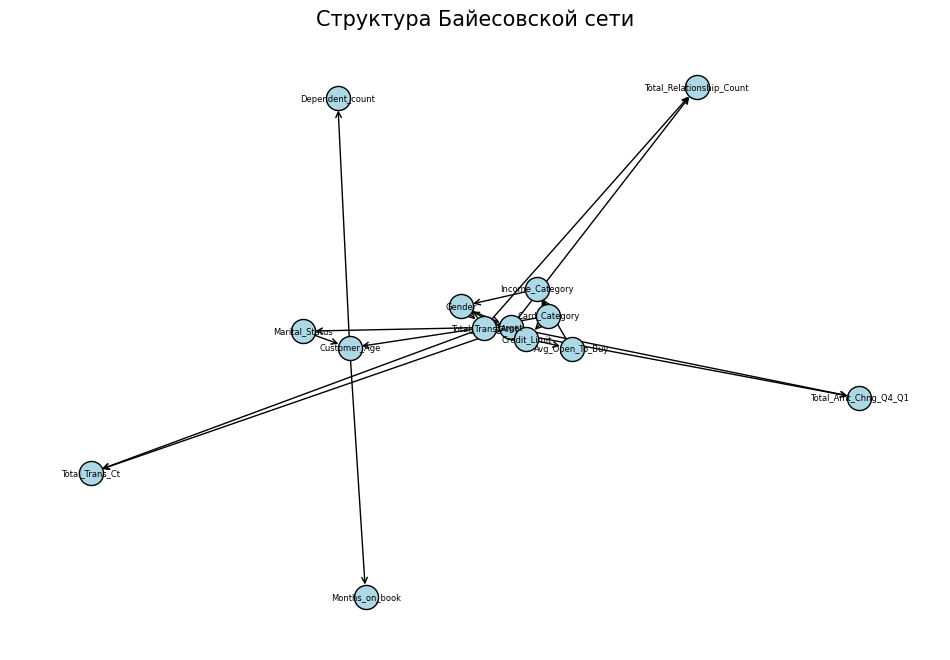

In [87]:
# Получаем структуру графа из модели
edges = best_model.edges()
G = nx.DiGraph()
G.add_edges_from(edges)

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G)
nx.draw_networkx_nodes(G, pos, node_size=300, node_color='lightblue', edgecolors='black')
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=10)
nx.draw_networkx_labels(G, pos, font_size=6, font_family='sans-serif')

plt.title("Структура Байесовской сети", fontsize=15)
plt.axis('off')
plt.show()

In [89]:
synthetic_samples_df.to_csv('./synthetic data/synthetic_data_BN_cls.csv', index=False)

 # Сравнение реальных и синтетических данных для задачи классификации

In [91]:
synthetic_data_ctgan = pd.read_csv('./synthetic data/synthetic_data_CTGAN_cls.csv')
synthetic_data_bamt = pd.read_csv('./synthetic data/synthetic_data_BN_cls.csv')
loaded_metadata = SingleTableMetadata.load_from_json('./data/metadata_cls.json')

synthetic_data_ctgan.shape, synthetic_data_bamt.shape 

((9114, 14), (9114, 14))

In [93]:
synthetic_data_bamt.dtypes

Gender                       object
Total_Trans_Amt             float64
target                        int64
Marital_Status               object
Customer_Age                  int64
Income_Category              object
Card_Category                object
Credit_Limit                float64
Avg_Open_To_Buy             float64
Total_Trans_Ct                int64
Total_Relationship_Count      int64
Total_Amt_Chng_Q4_Q1        float64
Months_on_book                int64
Dependent_count               int64
dtype: object

In [95]:
synthetic_data_ctgan.dtypes

Gender                       object
Dependent_count               int64
Marital_Status               object
Income_Category              object
Card_Category                object
Total_Relationship_Count      int64
Credit_Limit                float64
Avg_Open_To_Buy             float64
Total_Trans_Amt             float64
Total_Trans_Ct                int64
Customer_Age                  int64
Months_on_book                int64
Total_Amt_Chng_Q4_Q1        float64
target                        int64
dtype: object

In [97]:
real_data.dtypes

Gender                       object
Dependent_count               int64
Marital_Status               object
Income_Category              object
Card_Category                object
Total_Relationship_Count      int64
Credit_Limit                float64
Avg_Open_To_Buy             float64
Total_Trans_Amt             float64
Total_Trans_Ct                int64
Customer_Age                  int64
Months_on_book                int64
Total_Amt_Chng_Q4_Q1        float64
target                        int64
dtype: object

In [99]:
from sdv.evaluation.single_table import run_diagnostic

diagnostic_ctgan = run_diagnostic(
    real_data=real_data,
    synthetic_data=synthetic_data_ctgan,
    metadata=metadata
)

diagnostic_bamt = run_diagnostic(
    real_data=real_data,
    synthetic_data=synthetic_data_bamt,
    metadata=metadata
)

Generating report ...

(1/2) Evaluating Data Validity: |█████████████| 14/14 [00:00<00:00, 763.39it/s]|
Data Validity Score: 100.0%

(2/2) Evaluating Data Structure: |██████████████| 1/1 [00:00<00:00, 882.83it/s]|
Data Structure Score: 100.0%

Overall Score (Average): 100.0%

Generating report ...

(1/2) Evaluating Data Validity: |████████████| 14/14 [00:00<00:00, 1090.44it/s]|
Data Validity Score: 100.0%

(2/2) Evaluating Data Structure: |██████████████| 1/1 [00:00<00:00, 958.92it/s]|
Data Structure Score: 100.0%

Overall Score (Average): 100.0%



In [101]:
diagnostic_ctgan.get_details(property_name='Data Validity')

,Column,Metric,Score
0,Gender,CategoryAdherence,1.0
1,Dependent_count,CategoryAdherence,1.0
2,Marital_Status,CategoryAdherence,1.0
3,Income_Category,CategoryAdherence,1.0
4,Card_Category,CategoryAdherence,1.0
5,Total_Relationship_Count,CategoryAdherence,1.0
6,Credit_Limit,BoundaryAdherence,1.0
7,Avg_Open_To_Buy,BoundaryAdherence,1.0
8,Total_Trans_Amt,BoundaryAdherence,1.0
9,Total_Trans_Ct,BoundaryAdherence,1.0


In [103]:
diagnostic_bamt.get_details(property_name='Data Validity')

,Column,Metric,Score
0,Gender,CategoryAdherence,1.0
1,Dependent_count,CategoryAdherence,1.0
2,Marital_Status,CategoryAdherence,1.0
3,Income_Category,CategoryAdherence,1.0
4,Card_Category,CategoryAdherence,1.0
5,Total_Relationship_Count,CategoryAdherence,1.0
6,Credit_Limit,BoundaryAdherence,1.0
7,Avg_Open_To_Buy,BoundaryAdherence,1.0
8,Total_Trans_Amt,BoundaryAdherence,1.0
9,Total_Trans_Ct,BoundaryAdherence,1.0


In [105]:
from sdv.evaluation.single_table import evaluate_quality

quality_report_ctgan = evaluate_quality(
    real_data=real_data,
    synthetic_data=synthetic_data_ctgan,
    metadata=metadata
)

quality_report_bamt = evaluate_quality(
    real_data=real_data,
    synthetic_data=synthetic_data_bamt,
    metadata=metadata
)

Generating report ...

(1/2) Evaluating Column Shapes: |█████████████| 14/14 [00:00<00:00, 202.08it/s]|
Column Shapes Score: 91.65%

(2/2) Evaluating Column Pair Trends: |████████| 91/91 [00:00<00:00, 501.87it/s]|
Column Pair Trends Score: 83.71%

Overall Score (Average): 87.68%

Generating report ...

(1/2) Evaluating Column Shapes: |█████████████| 14/14 [00:00<00:00, 366.36it/s]|
Column Shapes Score: 91.88%

(2/2) Evaluating Column Pair Trends: |████████| 91/91 [00:00<00:00, 537.53it/s]|
Column Pair Trends Score: 88.0%

Overall Score (Average): 89.94%



In [107]:
ctgan_report = quality_report_ctgan.get_details('Column Shapes')
ctgan_report.rename(columns={'Score': 'CTGAN_score'}, inplace=True)

bamt_report = quality_report_bamt.get_details('Column Shapes')
bamt_report.rename(columns={'Score': 'BN_score'}, inplace=True)

adj_report = pd.concat([ctgan_report, bamt_report.BN_score], axis=1)
adj_report

,Column,Metric,CTGAN_score,BN_score
0,Gender,TVComplement,0.995721,0.905311
1,Dependent_count,TVComplement,0.915624,0.911784
2,Marital_Status,TVComplement,0.817753,0.971363
3,Income_Category,TVComplement,0.921878,0.874698
4,Card_Category,TVComplement,0.959293,0.995940
5,Total_Relationship_Count,TVComplement,0.820935,0.929120
6,Credit_Limit,KSComplement,0.883805,0.990674
7,Avg_Open_To_Buy,KSComplement,0.929449,0.782203
8,Total_Trans_Amt,KSComplement,0.921659,0.983213
9,Total_Trans_Ct,KSComplement,0.900592,0.870090


In [109]:
plot_cols = {'Gender': ['Credit_Limit', 'Total_Trans_Amt'],
            'Marital_Status': ['Total_Trans_Amt']}

sns.set_context("paper", rc={"axes.titlesize":30,"axes.labelsize":20, "legend.fontsize": 20, "xtick.labelsize":15, "ytick.labelsize":15})
for cat_name in plot_cols:
  cats = synthetic_data_ctgan[cat_name].value_counts().index
  for col in plot_cols[cat_name]:
    fig, ax= plt.subplots(1, len(cats), figsize=(10*len(cats), 10),)
    for i, cat in enumerate(cats):
      sns.distplot(X_train[X_train[cat_name]==cat][col], ax=ax[i], label='Real', color=REAL_COLOR)
      sns.distplot(synthetic_data_ctgan[synthetic_data_ctgan[cat_name]==cat][col], ax=ax[i], label='Fake CTGAN', color=CTGAN_COLOR)
      ax[i].grid(True)
      ax[i].set_title(f'{col} {cat}')
      ax[i].legend(loc=0)

In [110]:
plot_cols = {'Gender': ['Credit_Limit', 'Total_Trans_Amt'],
            'Marital_Status': ['Total_Trans_Amt']}

sns.set_context("paper", rc={"axes.titlesize":30,"axes.labelsize":20, "legend.fontsize": 20, "xtick.labelsize":15, "ytick.labelsize":15})
for cat_name in plot_cols:
  cats = synthetic_data_bamt[cat_name].value_counts().index
  for col in plot_cols[cat_name]:
    fig, ax= plt.subplots(1, len(cats), figsize=(10*len(cats), 10),)
    for i, cat in enumerate(cats):
      sns.distplot(X_train[X_train[cat_name]==cat][col], ax=ax[i], label='Real', color=REAL_COLOR)
      sns.distplot(synthetic_data_bamt[synthetic_data_bamt[cat_name]==cat][col], ax=ax[i], label='Fake BN', color=BAMT_COLOR)
      ax[i].grid(True)
      ax[i].set_title(f'{col} {cat}')
      ax[i].legend(loc=0)

In [113]:
cont_data = [ c for c in X_train.columns if c not in categorical_features]
cols = 2

rows = max(1 , len(cont_data) // cols) + 1

sns.set_context("paper", rc={"axes.titlesize":30,"axes.labelsize":20, "legend.fontsize": 20, "xtick.labelsize":1, "ytick.labelsize":15})

fig, ax= plt.subplots(rows, cols, figsize=(25, 6 * rows))

axes = ax.flatten()

for i, col in enumerate(cont_data):
  sns.distplot(X_train[col], ax=axes[i], label='Real', color = REAL_COLOR)
  sns.distplot(synthetic_data_ctgan[col], ax=axes[i], label='Fake CTGAN', color = CTGAN_COLOR)#, hist=False)
  sns.distplot(synthetic_data_bamt[col], ax=axes[i], label='Fake BN', color = BAMT_COLOR)

  axes[i].grid(True)
  axes[i].legend(loc=0)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should

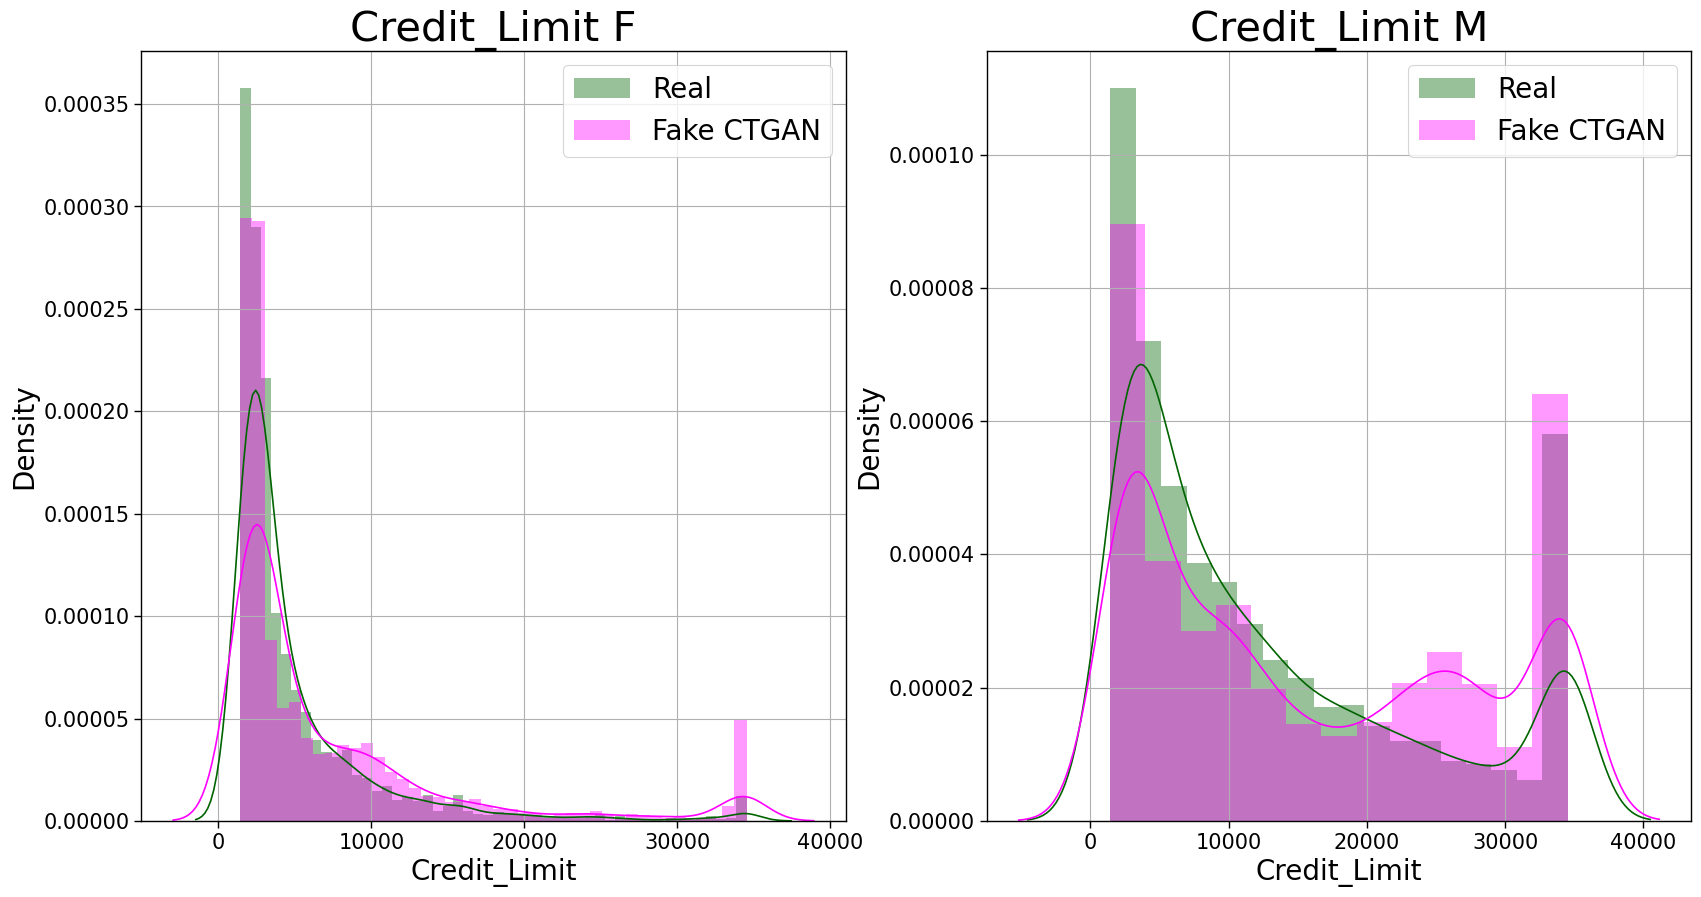

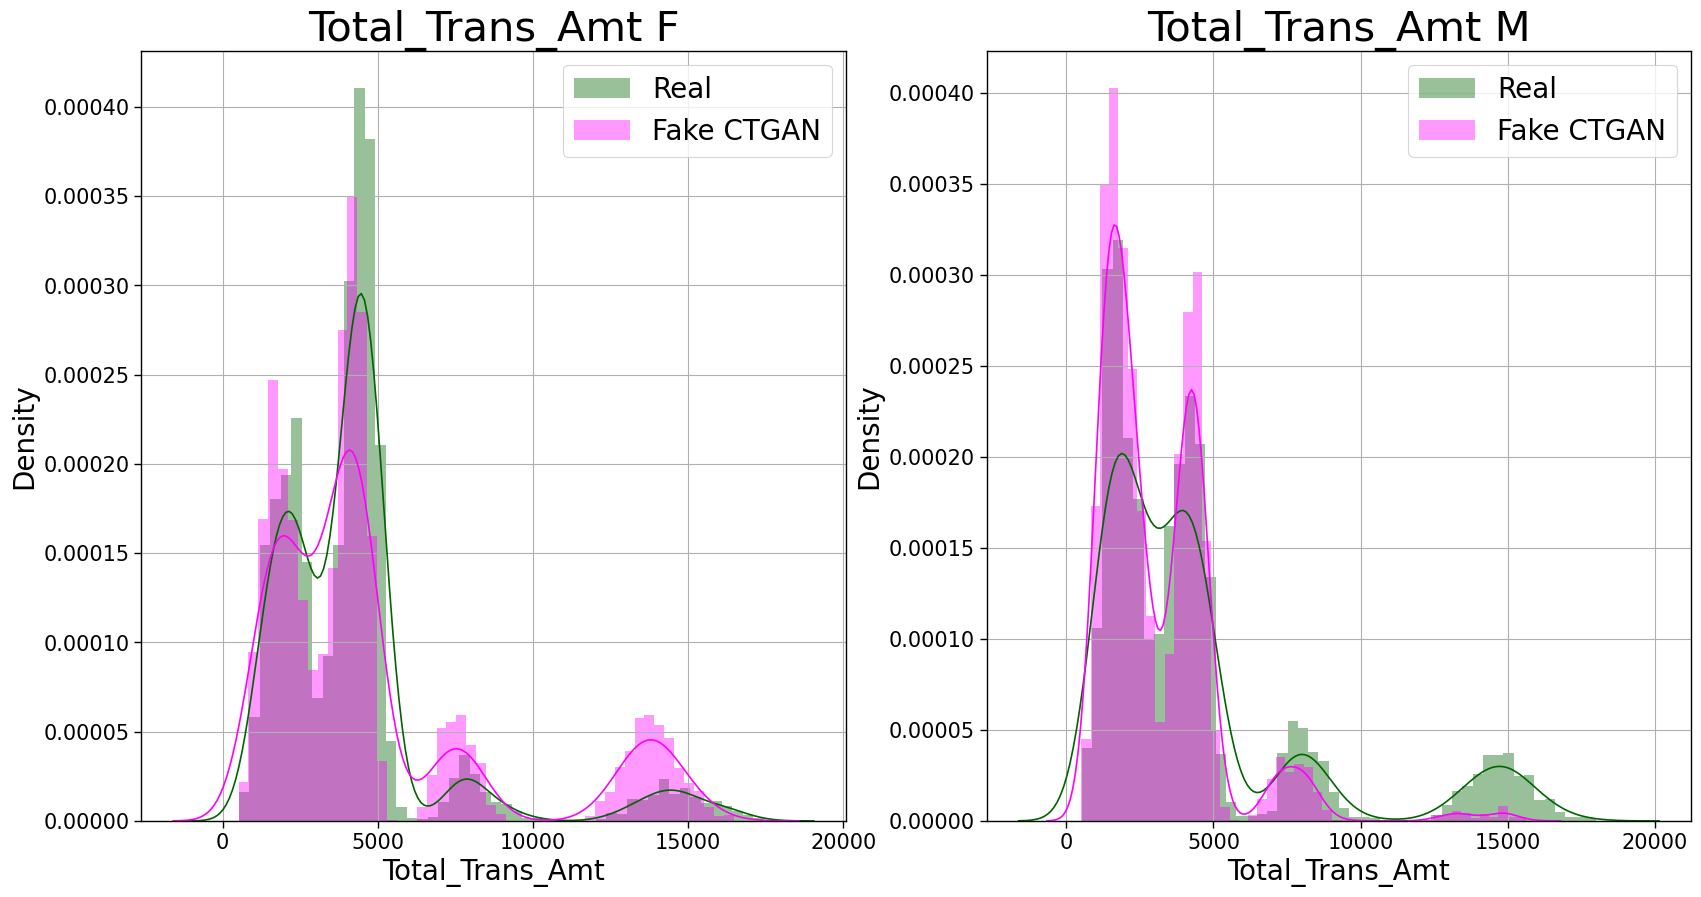

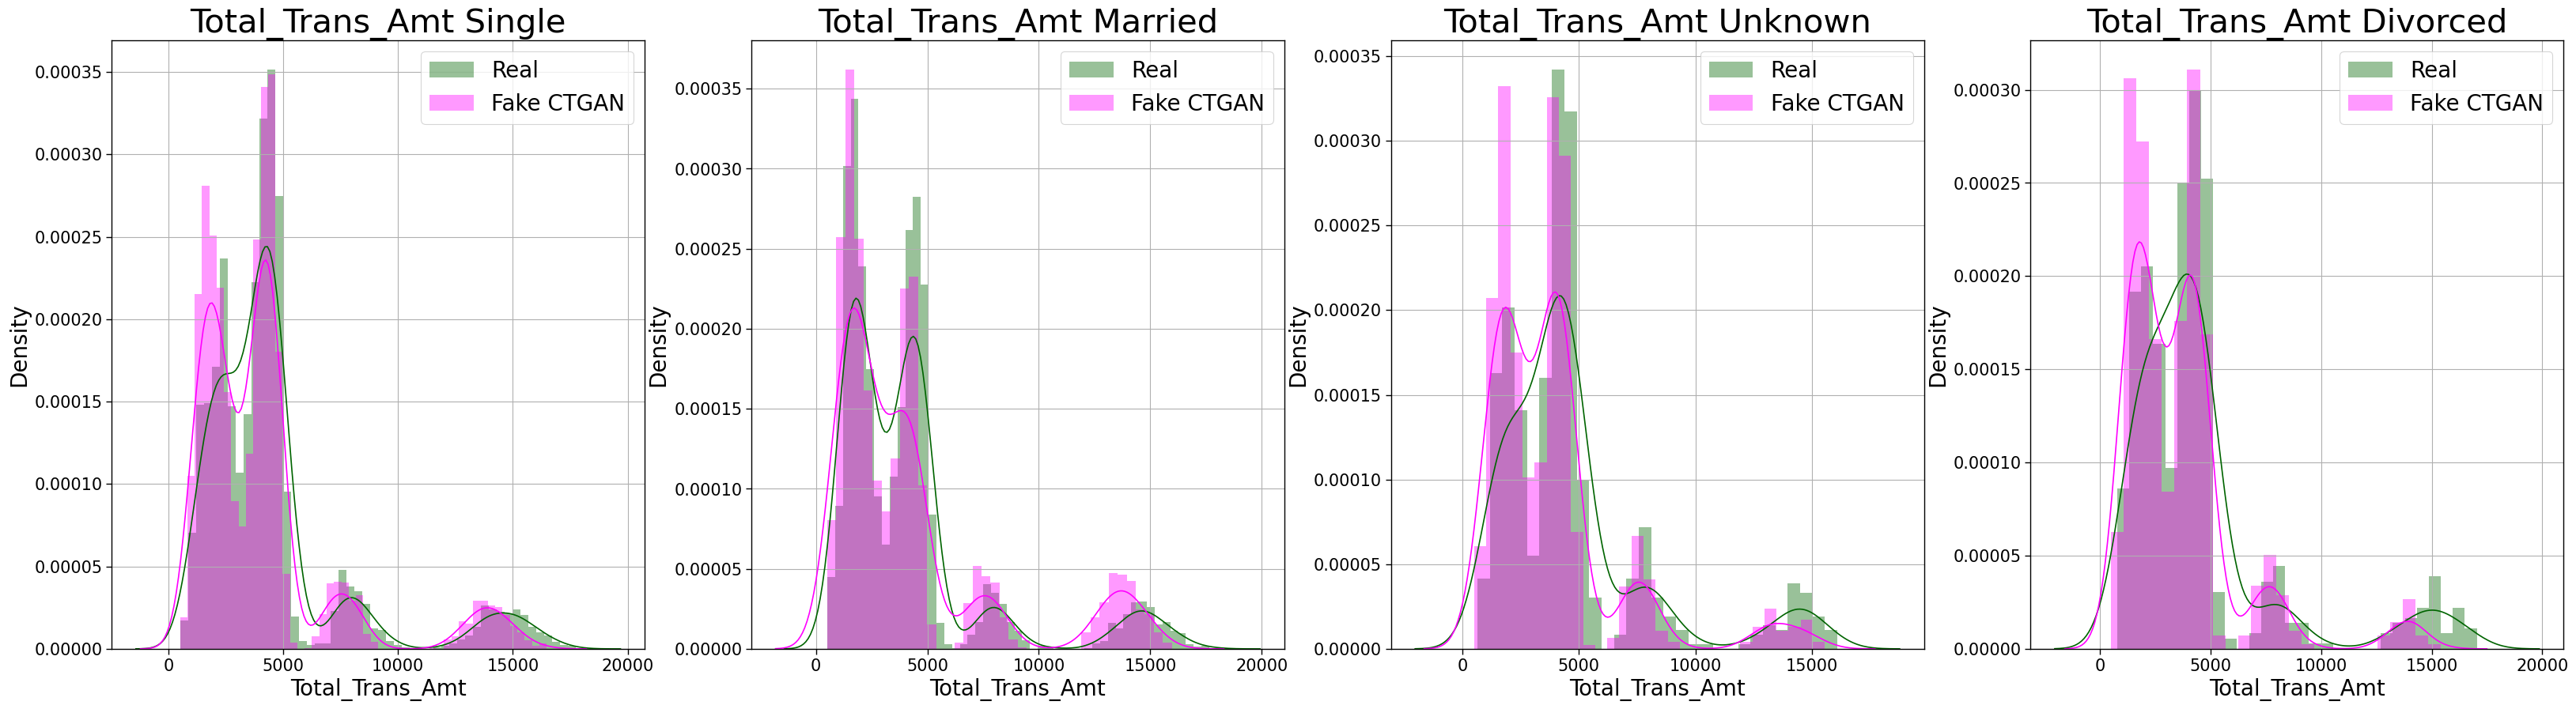

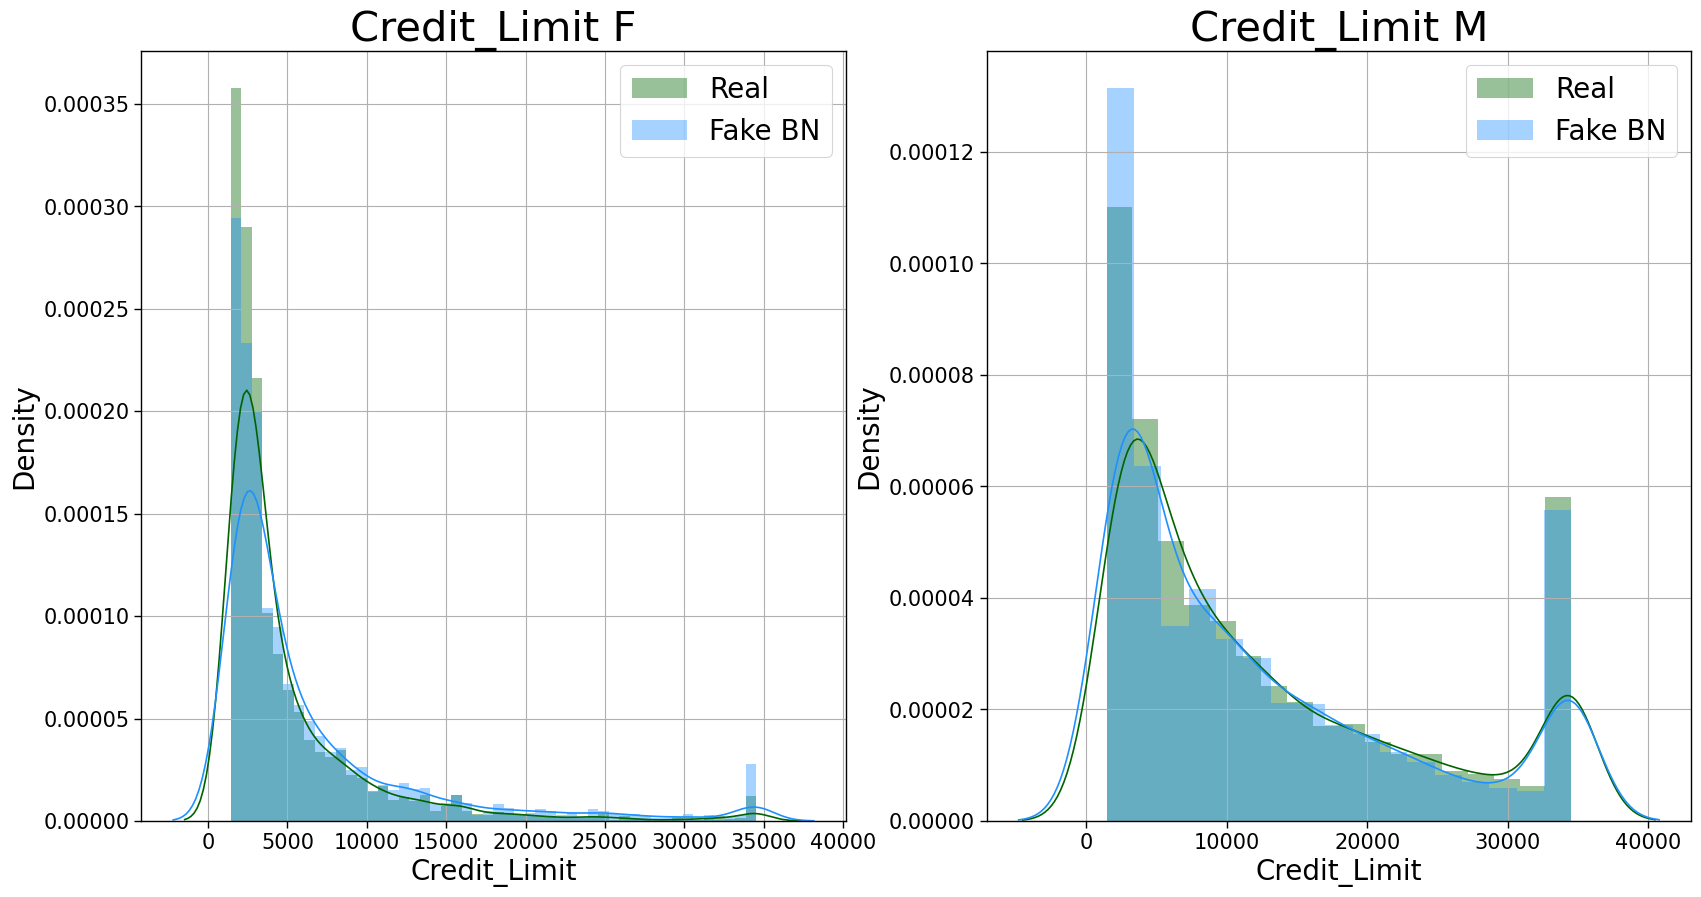

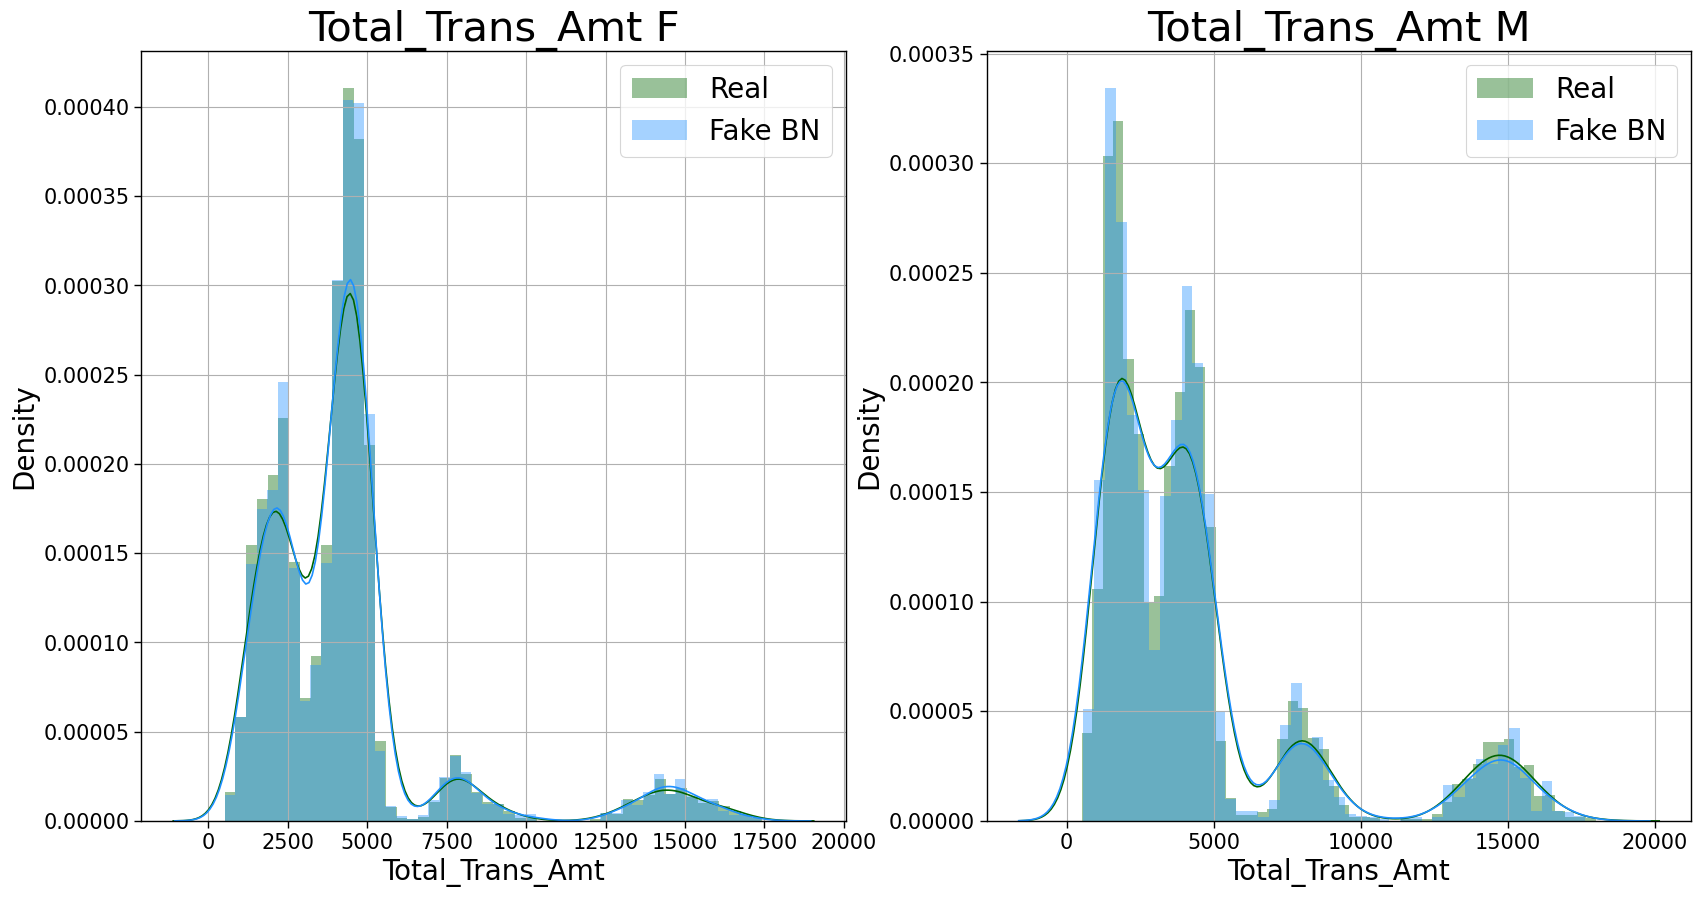

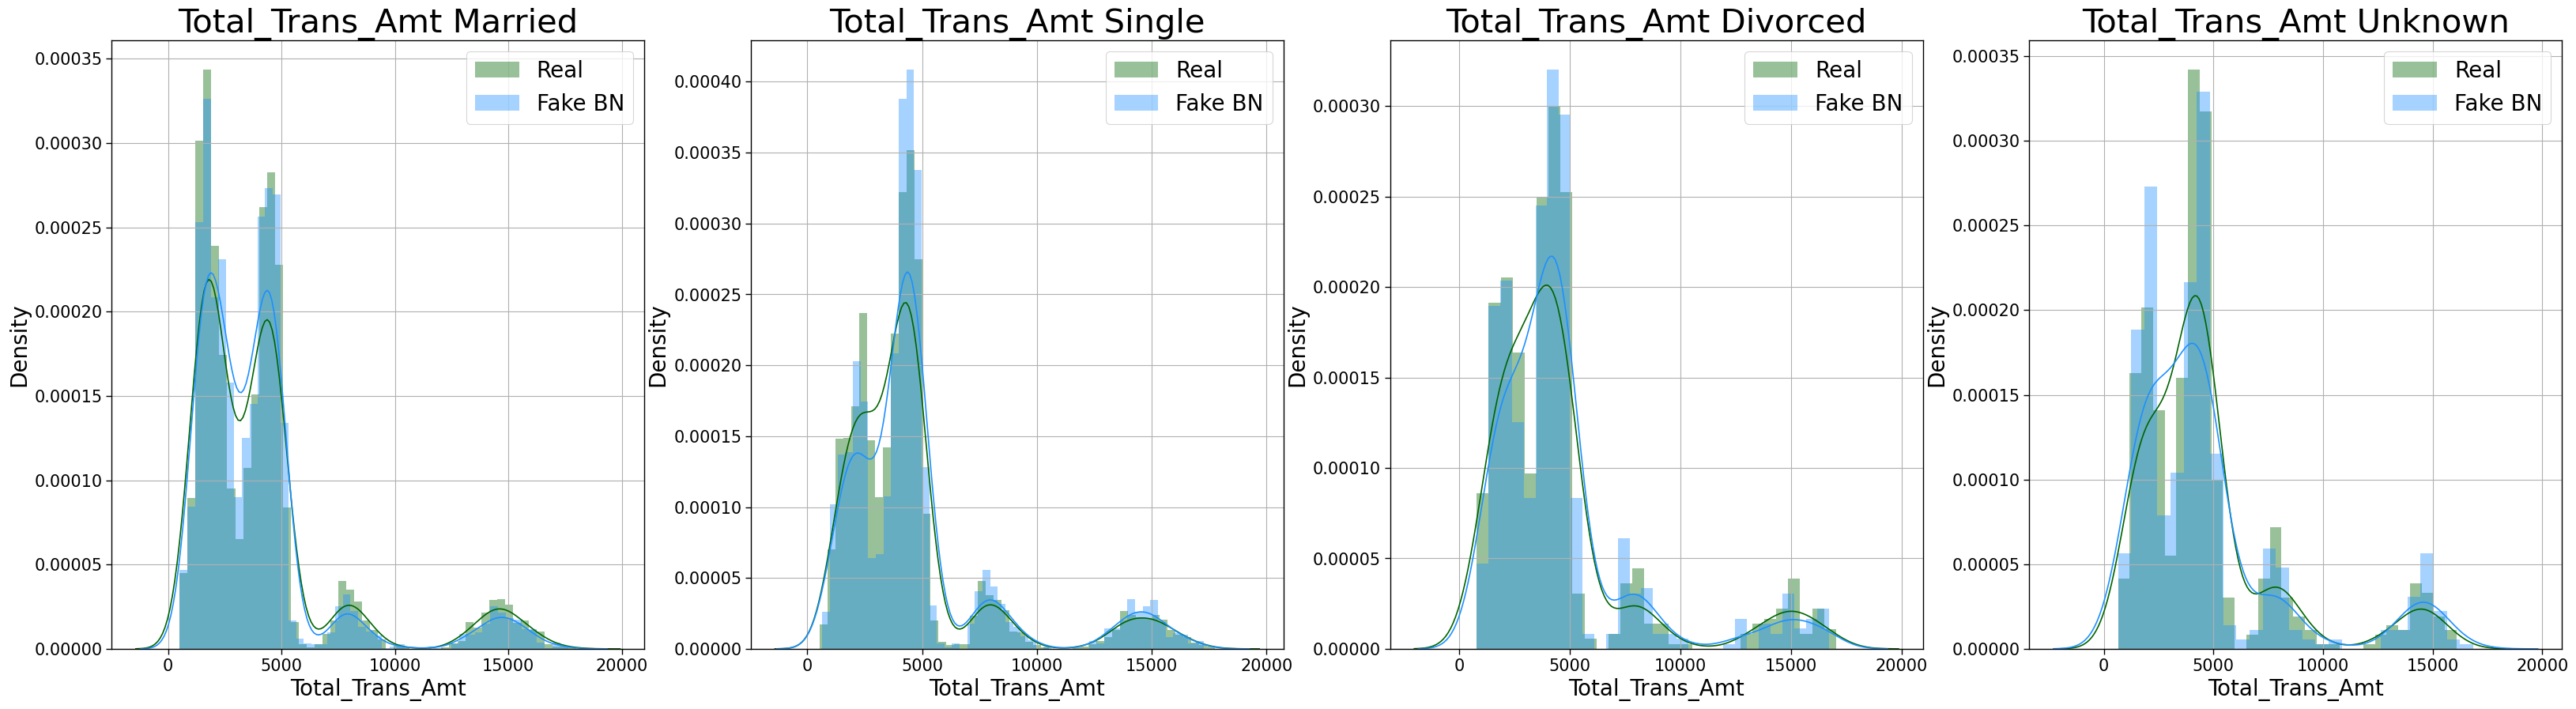

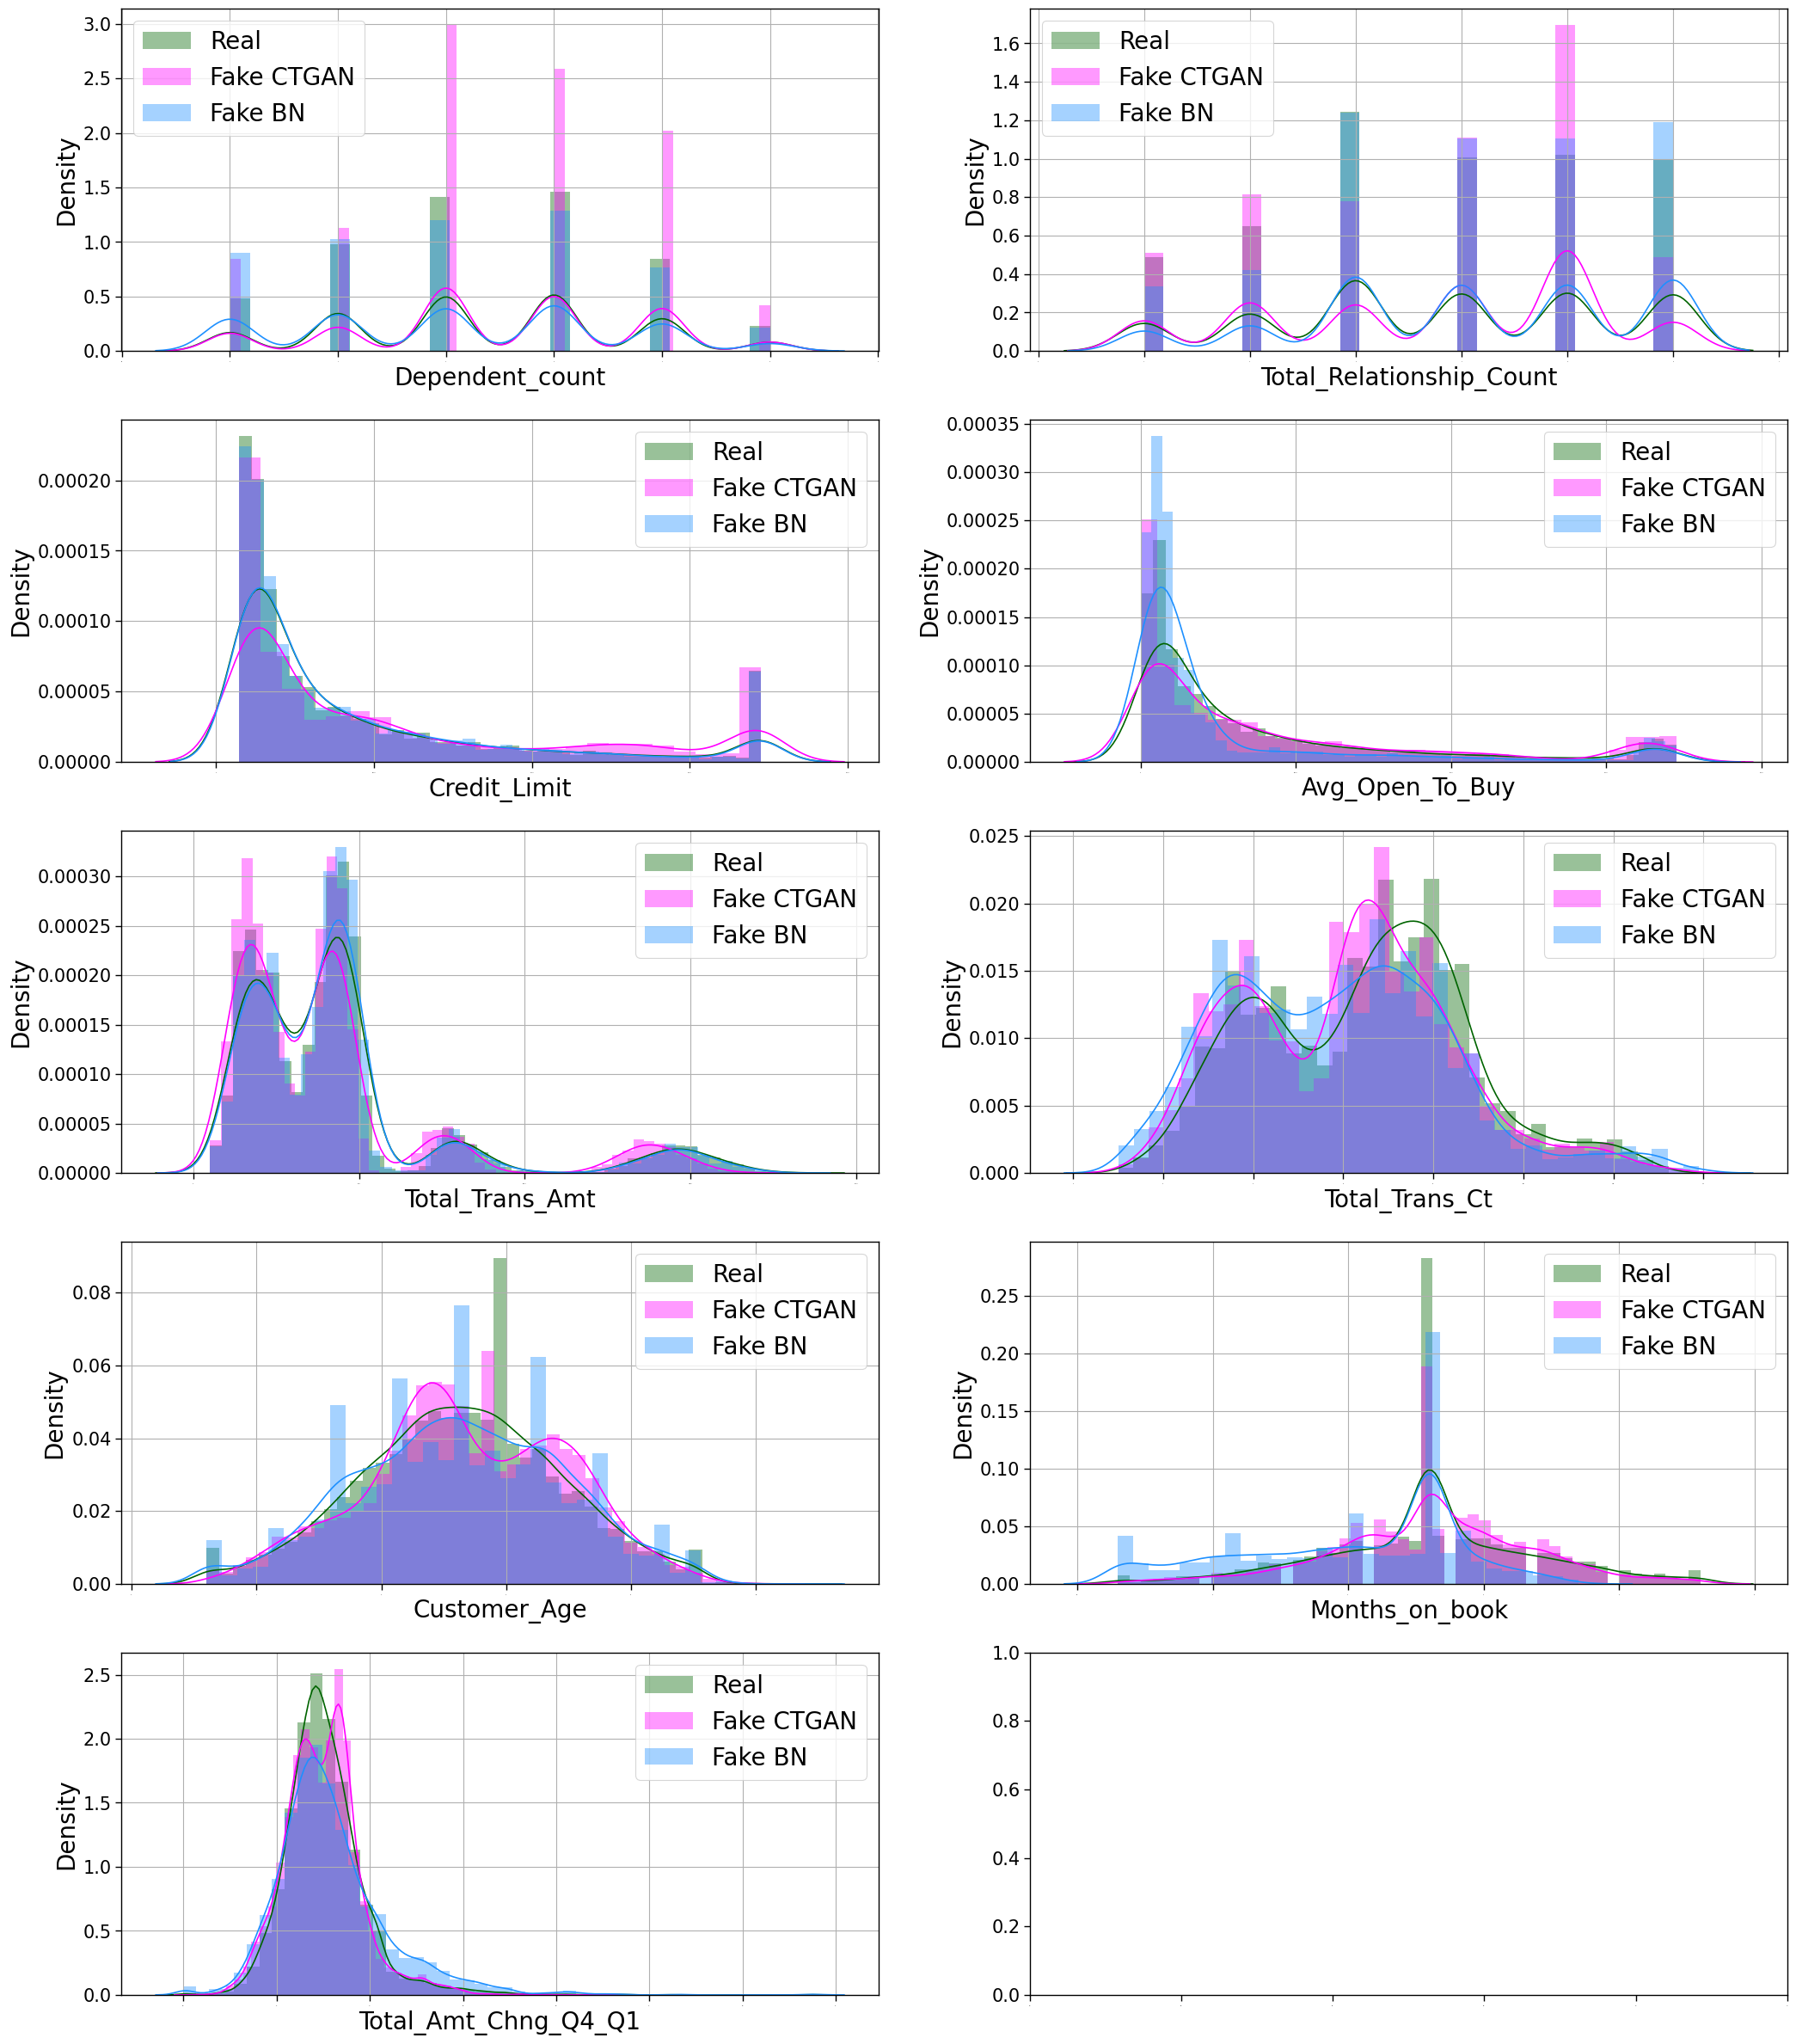

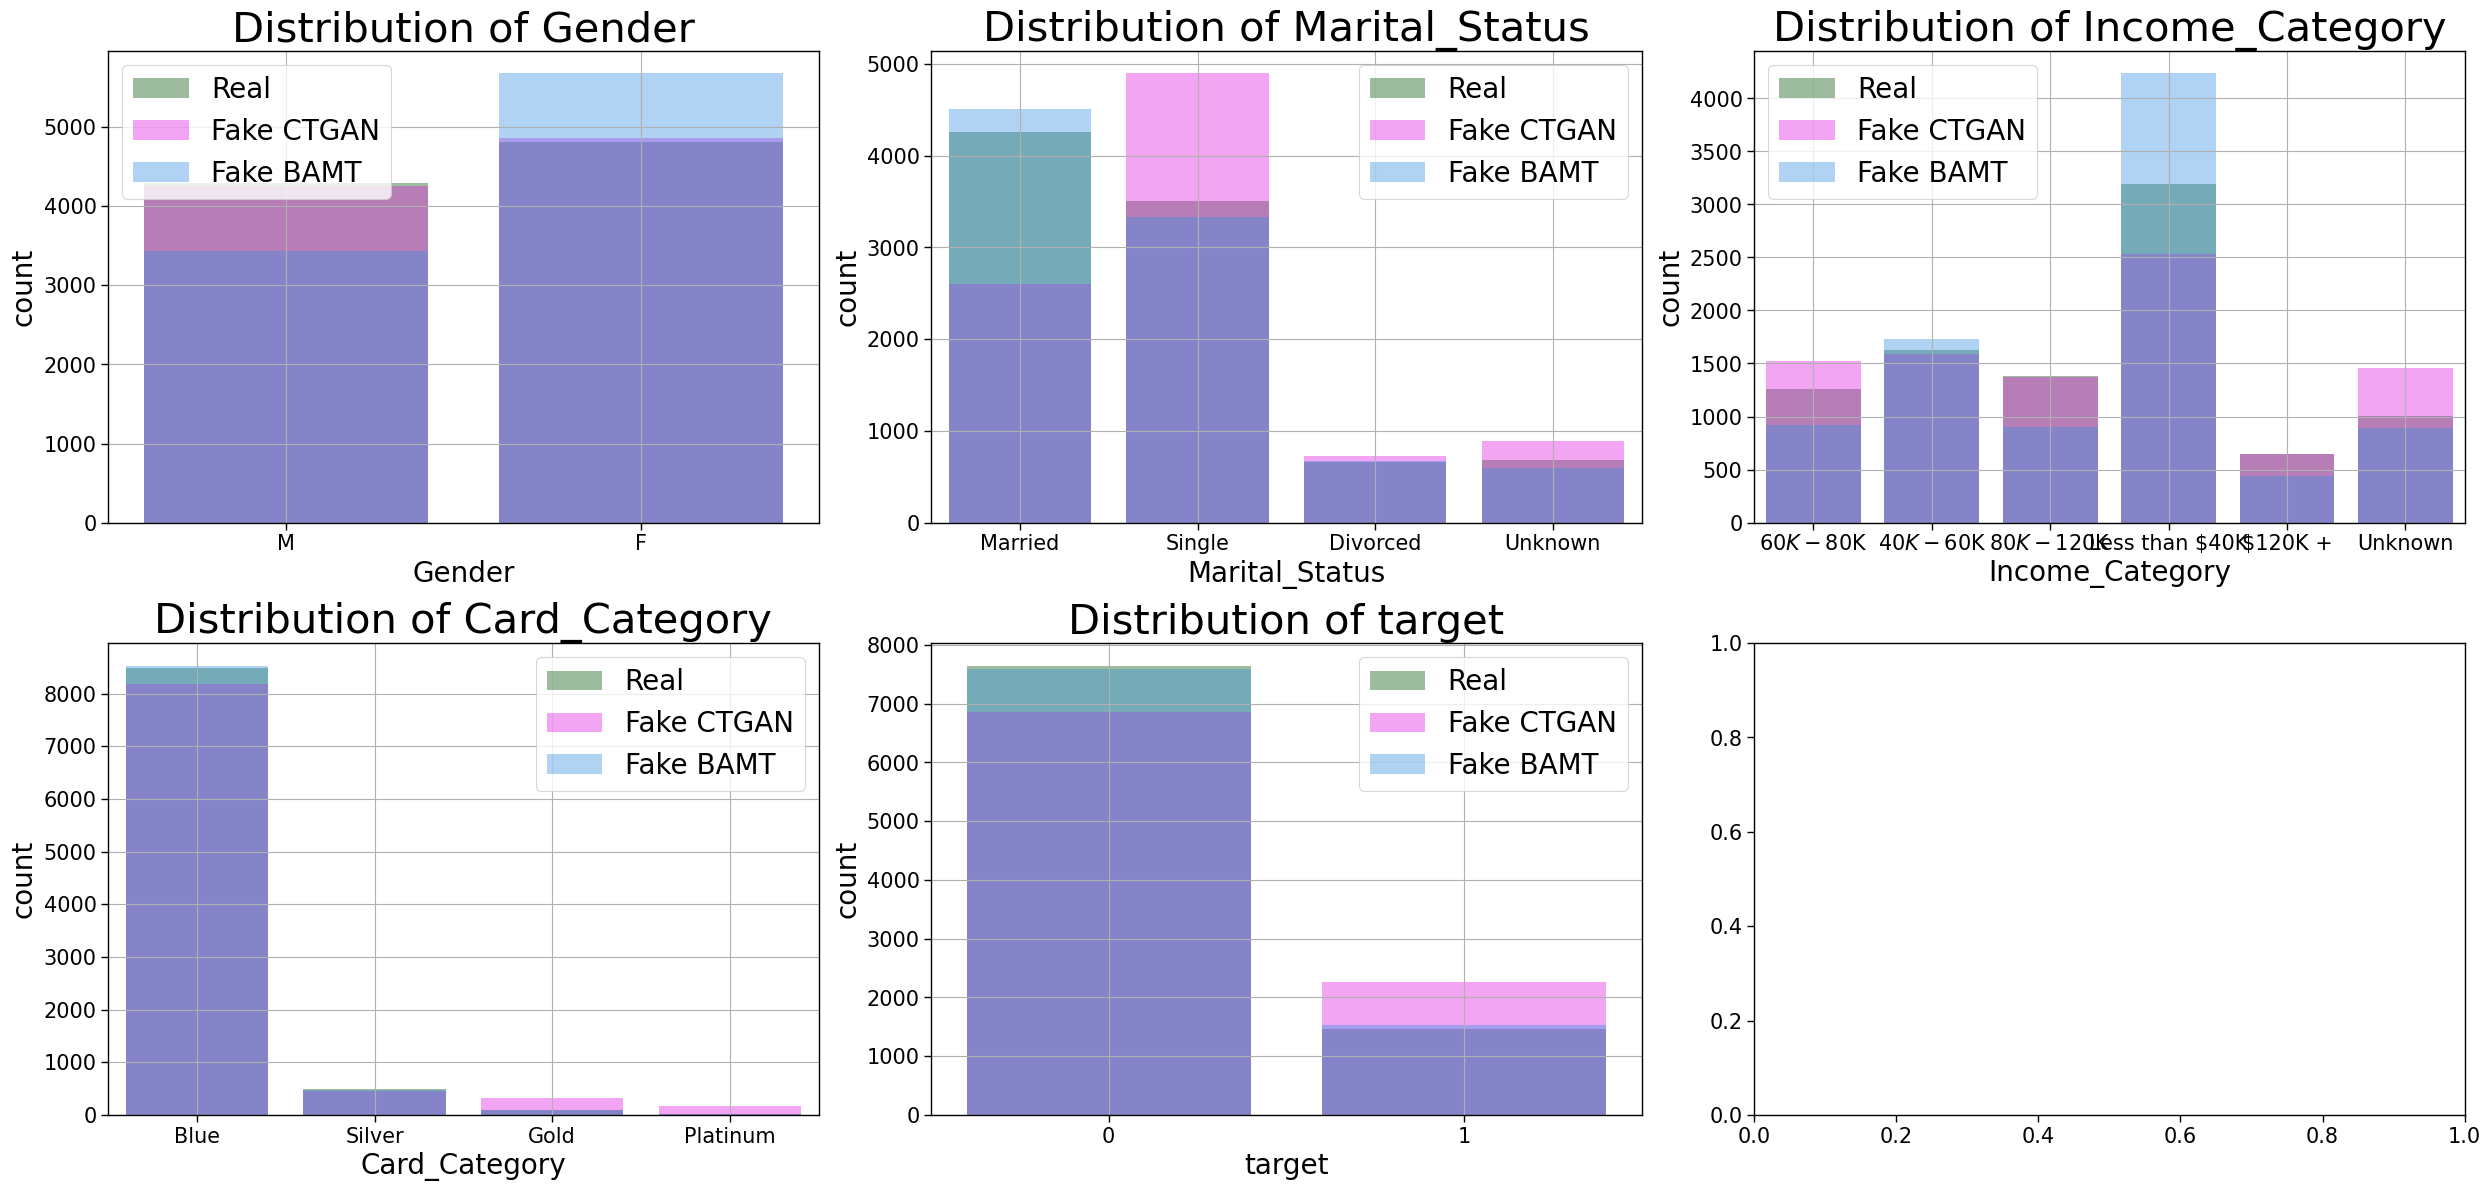

In [114]:
if 'target' not in categorical_features:
  categorical_features.append('target')

cols = 3
rows = (len(categorical_features) + cols - 1) // cols

sns.set_context("paper", rc={"axes.titlesize":30, "axes.labelsize":20, "legend.fontsize":20, "xtick.labelsize":15, "ytick.labelsize":15})

fig, ax = plt.subplots(rows, cols, figsize=(25, 6 * rows))
axes = ax.flatten()

for i, col in enumerate(categorical_features):
    sns.countplot(x=real_data[col], ax=axes[i], label='Real', color=REAL_COLOR, alpha=0.4)
    sns.countplot(x=synthetic_data_ctgan[col], ax=axes[i], label='Fake CTGAN', color=CTGAN_COLOR, alpha=0.4)
    sns.countplot(x=synthetic_data_bamt[col], ax=axes[i], label='Fake BAMT', color=BAMT_COLOR, alpha=0.4)

    axes[i].grid(True)
    axes[i].legend(loc=0)
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

In [115]:
fig, axes = plt.subplots(1, 3, figsize=(60, 15))

cmap = sns.color_palette("mako", as_cmap=True)

sns.heatmap(real_data.select_dtypes(exclude=['object']).corr(), ax=axes[0], annot=True, cmap=cmap)
sns.heatmap(synthetic_data_ctgan.select_dtypes(exclude=['object']).corr(), ax=axes[1], annot=True, cmap=cmap)
sns.heatmap(synthetic_data_bamt.select_dtypes(exclude=['object']).corr(), ax=axes[2], annot=True, cmap=cmap)

axes[0].set_title('Real')
axes[1].set_title('Fake CTGAN')
axes[2].set_title('Fake BAMT')
fig.show()

# Классификация. Предсказывание отточных клиентов

In [120]:
categorical_features = list(data.select_dtypes('object').columns)
categorical_features

['Gender', 'Marital_Status', 'Income_Category', 'Card_Category']

In [122]:
LR_pipe = Pipeline([
    ('encoding', ce.OrdinalEncoder(
       encoding_method='arbitrary', variables=categorical_features)),
    ('scaler', StandardScaler()),
    ('LR', LogisticRegression())
    ])

RF_pipe = Pipeline([
    ('encoding', ce.OrdinalEncoder(
       encoding_method='arbitrary', variables=categorical_features)),
    ('scaler', StandardScaler()),
    ('RF', RandomForestClassifier())
    ])

RFL_pipe = Pipeline([
    ('encoding', ce.OrdinalEncoder(
       encoding_method='ordered', variables=categorical_features)),
    ('scaler', StandardScaler()),
    ('RF', RandomForestRegressor())
    ])

In [124]:
for col in categorical_features:
    synthetic_data_bamt[col] = synthetic_data_bamt[col].astype('category')
    synthetic_data_ctgan[col] = synthetic_data_ctgan[col].astype('category')

In [126]:
right_pos_df_ctgan = pd.DataFrame()
right_pos_df_bn = pd.DataFrame()

for col in real_data.columns:
    right_pos_df_ctgan[col] = synthetic_data_ctgan[col]
    right_pos_df_bn[col] = synthetic_data_bamt[col]

synthetic_data_ctgan = right_pos_df_ctgan.copy()
synthetic_data_bamt = right_pos_df_bn.copy()

In [128]:
y_pred_test_initial_lr = fit_predict(LR_pipe, X_train.copy(), y_train, X_test, y_test)
y_pred_test_ctgan_lr = fit_predict(LR_pipe, synthetic_data_ctgan.drop(['target'], axis=1), synthetic_data_ctgan['target'], X_test, y_test)
y_pred_test_bamt_lr = fit_predict(LR_pipe, synthetic_data_bamt.drop(['target'], axis=1), synthetic_data_bamt['target'], X_test, y_test)

y_pred_test_initial_rf = fit_predict(RF_pipe, X_train.copy(), y_train, X_test, y_test)
y_pred_test_ctgan_rf = fit_predict(RF_pipe, synthetic_data_ctgan.drop(['target'], axis=1), synthetic_data_ctgan['target'], X_test, y_test)
y_pred_test_bamt_rf = fit_predict(RF_pipe, synthetic_data_bamt.drop(['target'], axis=1), synthetic_data_bamt['target'], X_test, y_test)

y_pred_test_initial_lgbm = lgbm_predict(X_train.copy(), y_train, X_test, y_test, categorical_features)
y_pred_test_ctgan_lgbm = lgbm_predict(synthetic_data_ctgan.drop(['target'], axis=1), synthetic_data_ctgan['target'], X_test, y_test, categorical_features)
y_pred_test_bamt_lgbm = lgbm_predict(synthetic_data_bamt.drop(['target'], axis=1), synthetic_data_bamt['target'], X_test, y_test, categorical_features)

[LightGBM] [Warning] categorical_feature is set=Gender,Marital_Status,Income_Category,Card_Category, categorical_column=0,2,3,4 will be ignored. Current value: categorical_feature=Gender,Marital_Status,Income_Category,Card_Category
[LightGBM] [Info] Number of positive: 1464, number of negative: 7650
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000261 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1264
[LightGBM] [Info] Number of data points in the train set: 9114, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.160632 -> initscore=-1.653533
[LightGBM] [Info] Start training from score -1.653533
[LightGBM] [Warning] categorical_feature is set=Gender,Marital_Status,Income_Category,Card_Category, categorical_column=0,2,3,4 will be ignored. Current value: categorical_feature=Gender,Marital_Status,Income_Cate

# Классификация. Графики сравнения качества моделей

In [131]:
df_lr = pd.DataFrame(data=[roc_auc_score(y_test,  y_pred_test_initial_lr), roc_auc_score(y_test,  y_pred_test_ctgan_lr), roc_auc_score(y_test,  y_pred_test_bamt_lr)],
                     columns = ['Test'],
                     index = ['Initial', 'CTGAN', 'BAMT'])
df_lr['model']='LR'

df_rf = pd.DataFrame(data=[roc_auc_score(y_test,  y_pred_test_initial_rf), roc_auc_score(y_test,  y_pred_test_ctgan_rf), roc_auc_score(y_test,  y_pred_test_bamt_rf)],
                     columns = ['Test'],
                     index = ['Initial', 'CTGAN', 'BAMT'])
df_rf['model']='RF'

df_lgbm = pd.DataFrame(data=[roc_auc_score(y_test,  y_pred_test_initial_lgbm), roc_auc_score(y_test,  y_pred_test_ctgan_lgbm), roc_auc_score(y_test,  y_pred_test_bamt_lgbm)],
                   columns = ['Test'],
                      index = ['Initial', 'CTGAN', 'BAMT'])
df_lgbm['model']='Lgbm'

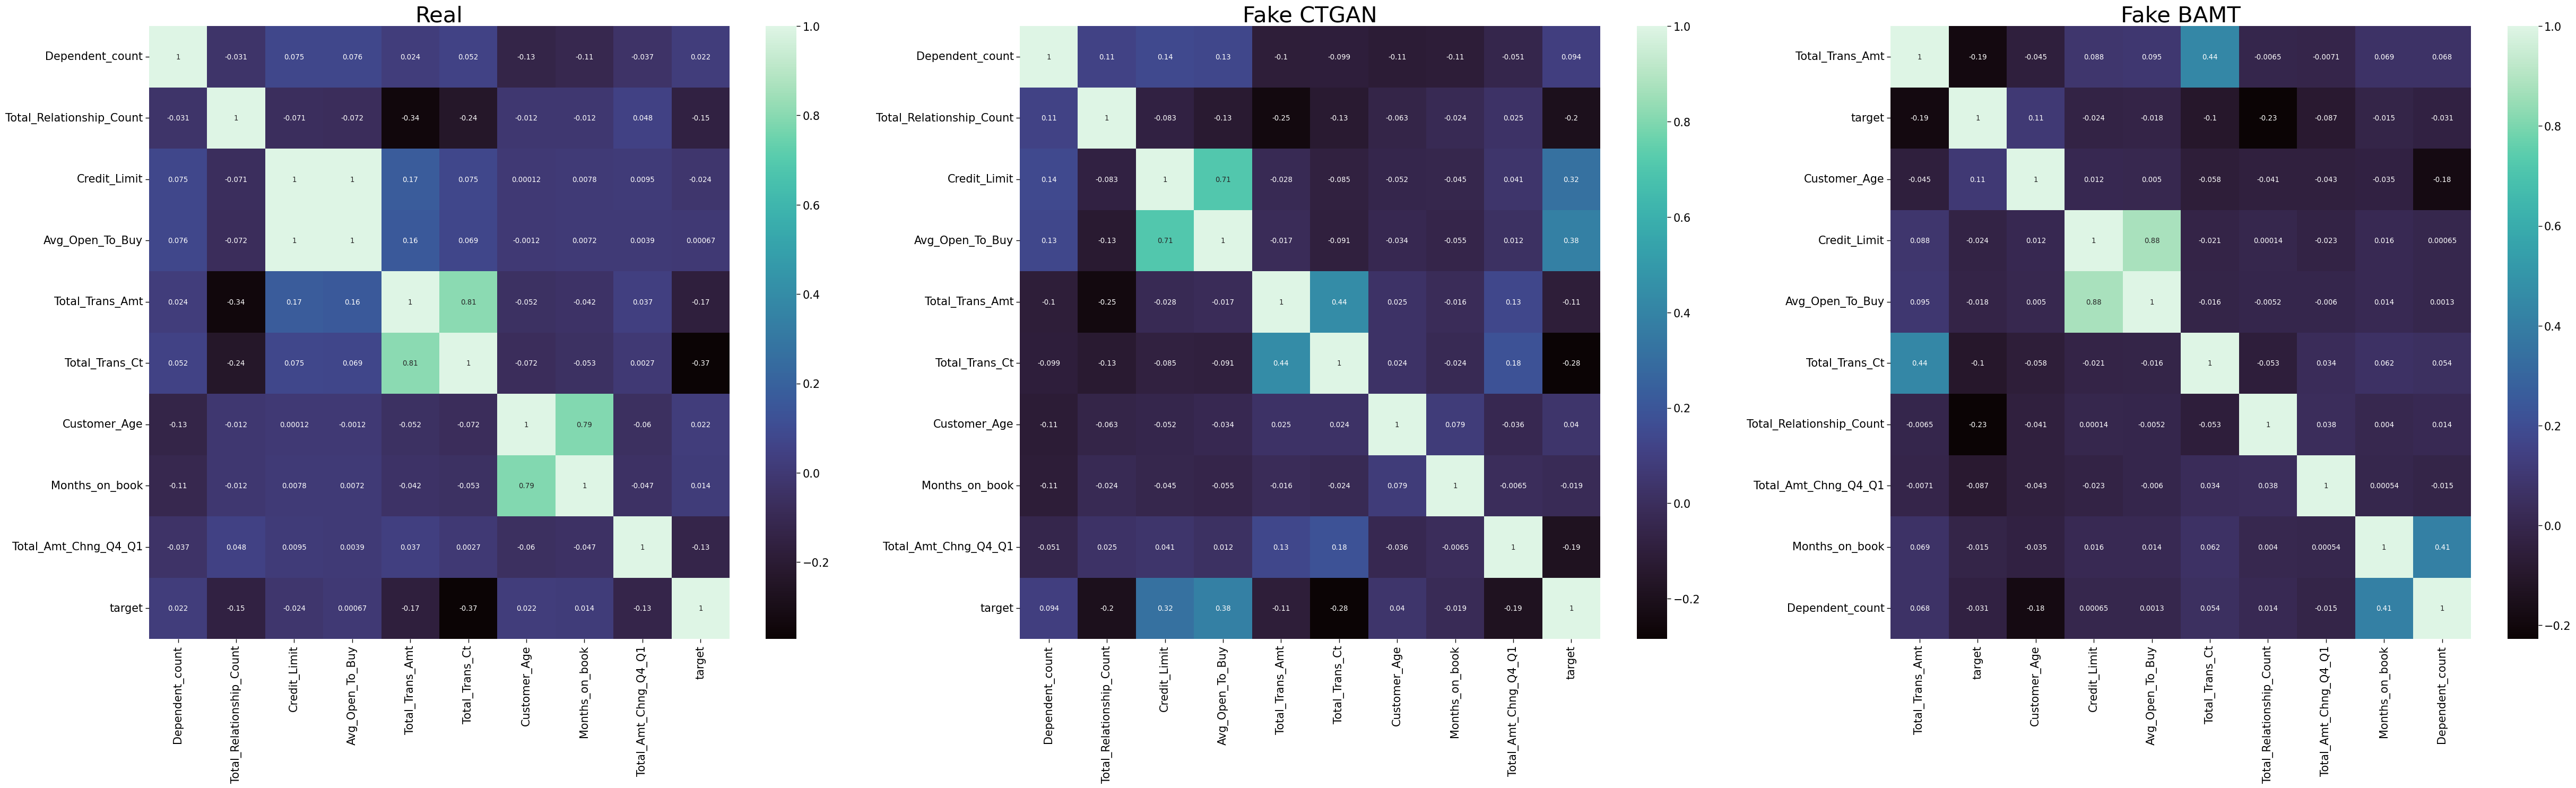

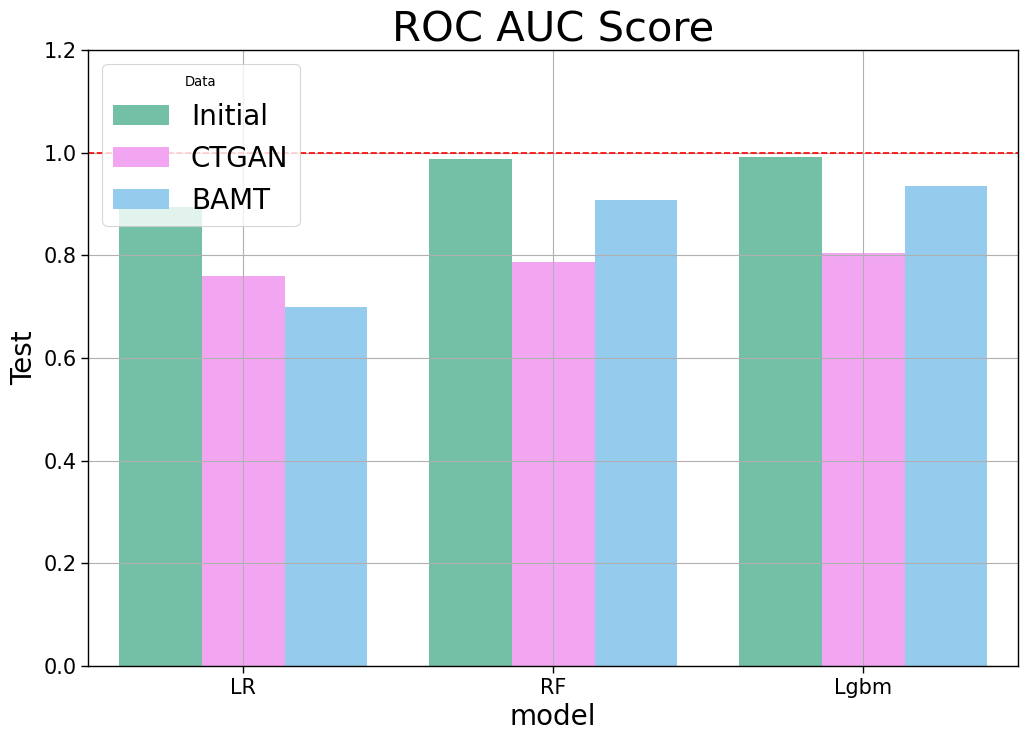

In [133]:
df=pd.concat([df_lr, df_rf, df_lgbm])
df.index.rename('Data', inplace=True)
df.reset_index(inplace=True)

fig = plt.figure(figsize=(12,8))
sns.barplot(x = 'model', y = 'Test', hue = 'Data', data = df, palette=['#66CDAA', '#FF99FF', '#87CEFA'])
plt.plot([-0.5, 2.5], [1, 1], color="red", linestyle="--")
plt.title('ROC AUC Score')
plt.xlim([-0.5,2.5])
plt.ylim([0,1.2])
plt.grid()
plt.show()

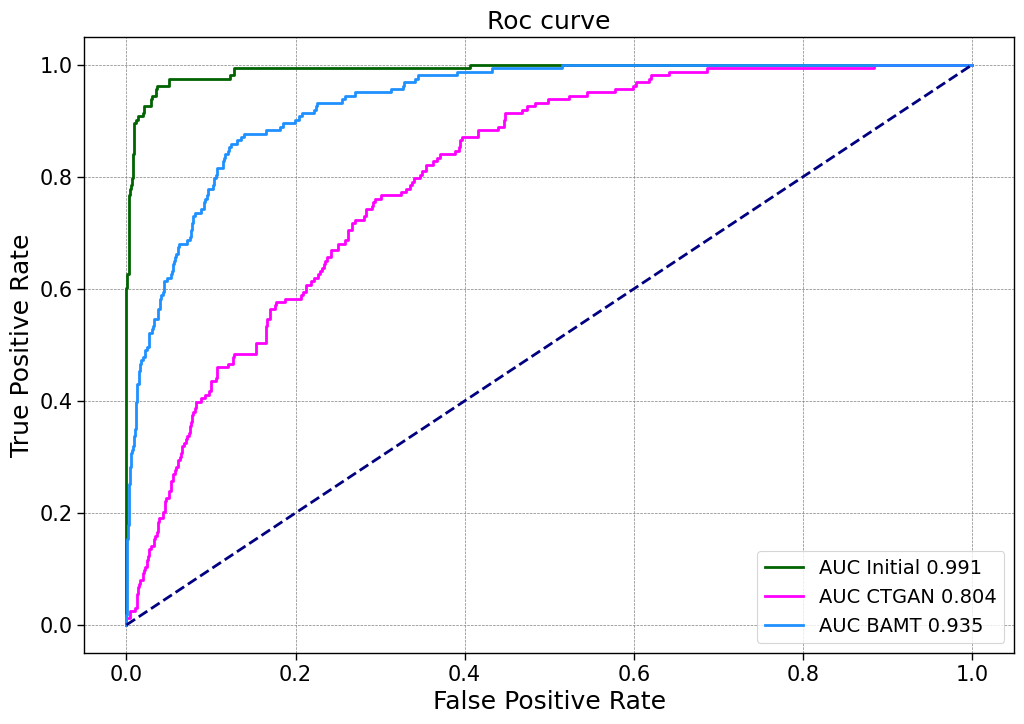

In [135]:
y_plot={'Initial': [y_test, y_pred_test_initial_lgbm],
        'CTGAN': [y_test, y_pred_test_ctgan_lgbm],
        'BAMT': [y_test, y_pred_test_bamt_lgbm]}
plot_roc_curve(y_plot)

# Загрузка данных для задачи регрессии

In [138]:
data = pd.read_csv('./data/California_airbnb.csv')
data.drop(columns=['Date', 'id', 'scrape_id', 'calendar_last_scraped', 'name',
                   'host_id', 'host_since', 'latitude', 'longitude', 'first_review',
                   'last_review', 'amenities', 'Country', 'Zone', 'host_city', 'host_country', 'room_type', 'bathrooms_text'], inplace=True)
data.head()

,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,host_total_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood_cleansed,property_type,...,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,bedrooms,City
0,NaN,NaN,50.0,0.0,1.0,3.0,1.0,1.0,Culver City,Entire condo,...,5.00,4.00,0,1,1,0,0,0.01,2.0,los-angeles
1,NaN,NaN,100.0,1.0,2.0,3.0,1.0,1.0,Hollywood,Private room in rental unit,...,4.95,4.88,1,2,0,2,0,0.35,1.0,los-angeles
2,within an hour,100.0,42.0,0.0,2.0,2.0,1.0,1.0,Santa Monica,Private room in rental unit,...,4.91,4.22,0,2,1,1,0,0.16,2.0,los-angeles
3,NaN,NaN,NaN,0.0,1.0,1.0,1.0,1.0,Bellflower,Entire rental unit,...,NaN,NaN,0,1,1,0,0,NaN,NaN,los-angeles
4,within an hour,100.0,96.0,1.0,3.0,4.0,1.0,1.0,Hollywood Hills,Private room in home,...,4.97,4.90,0,3,1,2,0,1.02,NaN,los-angeles


In [140]:
data.shape

(247859, 44)

In [142]:
data.isna().mean()

host_response_time                              0.185884
host_response_rate                              0.185884
host_acceptance_rate                            0.159635
host_is_superhost                               0.087723
host_listings_count                             0.000121
host_total_listings_count                       0.000121
host_has_profile_pic                            0.000121
host_identity_verified                          0.000121
neighbourhood_cleansed                          0.000000
property_type                                   0.000000
accommodates                                    0.000000
beds                                            0.018043
price                                           0.010926
minimum_nights                                  0.000000
maximum_nights                                  0.000000
minimum_minimum_nights                          0.000024
maximum_minimum_nights                          0.000024
minimum_maximum_nights         

In [144]:
for col in data.columns:
    if data[col].isna().mean() >= 0.8:
        print(col)
        data.drop([col], axis=1, inplace=True)

In [146]:
data.dtypes.value_counts()

float64    25
int64      15
object      4
Name: count, dtype: int64

In [148]:
for col in data.isna().mean()[data.isna().mean() > 0].index:
    if data[col].dtype == 'object':
        data[col].fillna('Unknown', inplace=True)
    else:
        m = data[col].mode()[0]
        data[col].fillna(m, inplace=True)

In [150]:
bin_float_cols = [col for col in data if data[col].nunique() == 2 and data[col].dtype == 'float']

disc_float_cols = ['host_response_rate', 'host_acceptance_rate', 'host_listings_count', 'host_total_listings_count', 'beds',
'price', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'bedrooms']

data[bin_float_cols + disc_float_cols] = data[bin_float_cols + disc_float_cols].astype(int)
data.price = data.price.astype(float)

In [152]:
cat_features = list(data.loc[:, data.dtypes == object].columns)
print(cat_features)

for col in cat_features:
      if data[col].nunique() > 10:
        print(col, '-', data[col].nunique())

['host_response_time', 'neighbourhood_cleansed', 'property_type', 'City']
neighbourhood_cleansed - 558
property_type - 125


In [154]:
data_1 = data.copy()

In [156]:
data_1 = data_1[data_1.neighbourhood_cleansed.isin(data_1.neighbourhood_cleansed.value_counts()[:7].index.to_list())]
data_1 = data_1[data_1.property_type.isin(data_1.property_type.value_counts()[:7].index.to_list())]
data_1.shape

(32014, 44)

In [158]:
data.select_dtypes('object').columns

Index(['host_response_time', 'neighbourhood_cleansed', 'property_type',
       'City'],
      dtype='object')

In [160]:
data.select_dtypes('float').columns

Index(['price', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm',
       'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_checkin',
       'review_scores_communication', 'review_scores_location',
       'review_scores_value', 'reviews_per_month'],
      dtype='object')

In [162]:
data.select_dtypes('int').columns

Index(['host_response_rate', 'host_acceptance_rate', 'host_is_superhost',
       'host_listings_count', 'host_total_listings_count',
       'host_has_profile_pic', 'host_identity_verified', 'accommodates',
       'beds', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights',
       'maximum_minimum_nights', 'minimum_maximum_nights',
       'maximum_maximum_nights', 'has_availability', 'availability_30',
       'availability_60', 'availability_90', 'availability_365',
       'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d',
       'instant_bookable', 'calculated_host_listings_count',
       'calculated_host_listings_count_entire_homes',
       'calculated_host_listings_count_private_rooms',
       'calculated_host_listings_count_shared_rooms', 'bedrooms'],
      dtype='object')

In [164]:
for col in data.select_dtypes('object').columns:
    print(data_1[col].value_counts(dropna=False))

host_response_time
within an hour        20761
Unknown                5863
within a few hours     3417
within a day           1549
a few days or more      424
Name: count, dtype: int64
neighbourhood_cleansed
San Jose                7181
Mission Bay             4594
Hollywood               4291
Long Beach              4120
Venice                  4087
Beverly Hills           3879
Unincorporated Areas    3862
Name: count, dtype: int64
property_type
Entire rental unit             10793
Entire home                     9597
Private room in home            4443
Entire condo                    3000
Entire guesthouse               1780
Private room in rental unit     1367
Entire guest suite              1034
Name: count, dtype: int64
City
los-angeles           16377
santa-clara-county     7946
san-diego              4594
santa-cruz-county      2071
san-mateo-county       1026
Name: count, dtype: int64


In [166]:
f_list = [data_1.select_dtypes(exclude=['int', 'float']),
          data_1[['price', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness',
                 'review_scores_location', 'review_scores_communication', 'reviews_per_month']],
          data_1[['bedrooms', 'accommodates', 'beds', 'host_acceptance_rate', 'host_is_superhost', 'number_of_reviews']]]

data_1 = pd.concat(f_list, axis=1)

data_1 = data_1.sample(30000, random_state=42).reset_index(drop=True)
data_1.shape

(30000, 17)

In [168]:
data_1.columns

Index(['host_response_time', 'neighbourhood_cleansed', 'property_type', 'City',
       'price', 'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_location',
       'review_scores_communication', 'reviews_per_month', 'bedrooms',
       'accommodates', 'beds', 'host_acceptance_rate', 'host_is_superhost',
       'number_of_reviews'],
      dtype='object')

In [170]:
for col in cat_features:
    print(col, '-', data_1[col].nunique())

host_response_time - 5
neighbourhood_cleansed - 7
property_type - 7
City - 5


In [172]:
data_1.dtypes.value_counts()

float64    7
int64      6
object     4
Name: count, dtype: int64

In [174]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(data_1.drop(['price'], axis=1),
                                                    data_1['price'], test_size=0.1,
                                                    shuffle=True,
                                                    random_state=42)

In [176]:
X_train.shape, X_test.shape

((27000, 16), (3000, 16))

In [178]:
real_data = X_train.copy()
real_data['price'] = y_train

# Генерация синтетических данных при помощи CTGAN для задачи регрессии

In [181]:
metadata = SingleTableMetadata()
metadata.detect_from_dataframe(data_1)
python_dict = metadata.to_dict()

INFO:sdv.metadata.single_table:Detected metadata:
INFO:sdv.metadata.single_table:{
    "METADATA_SPEC_VERSION": "SINGLE_TABLE_V1",
    "columns": {
        "host_response_time": {
            "sdtype": "categorical"
        },
        "neighbourhood_cleansed": {
            "sdtype": "categorical"
        },
        "property_type": {
            "sdtype": "categorical"
        },
        "City": {
            "sdtype": "city",
            "pii": true
        },
        "price": {
            "sdtype": "numerical"
        },
        "review_scores_rating": {
            "sdtype": "numerical"
        },
        "review_scores_accuracy": {
            "sdtype": "numerical"
        },
        "review_scores_cleanliness": {
            "sdtype": "numerical"
        },
        "review_scores_location": {
            "sdtype": "numerical"
        },
        "review_scores_communication": {
            "sdtype": "numerical"
        },
        "reviews_per_month": {
            "sdtype": "nume

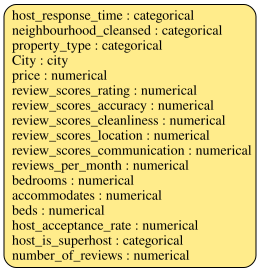

In [183]:
metadata.visualize()

In [185]:
metadata.update_columns_metadata(
    column_metadata={
        'City': {'sdtype': 'categorical'},
    },
)

In [187]:
metadata.save_to_json('./data/metadata_reg.json')

ValueError: A file named 'metadata_reg.json' already exists in this folder. Please specify a different filename.

In [189]:
%%time
ctgan_model_reg = CTGANSynthesizer(
    metadata,
    enforce_rounding=True,
    epochs=50,
    verbose=True,
    enforce_min_max_values=True
)
ctgan_model_reg.fit(real_data)

synthetic_data = ctgan_model_reg.sample(num_rows=real_data.shape[0])
synthetic_data.head()

INFO:SingleTableSynthesizer:{'EVENT': 'Instance', 'TIMESTAMP': datetime.datetime(2025, 3, 8, 12, 19, 30, 639363), 'SYNTHESIZER CLASS NAME': 'CTGANSynthesizer', 'SYNTHESIZER ID': 'CTGANSynthesizer_1.18.0_6c7f5251350d438a9298438e701f090a'}
INFO:SingleTableSynthesizer:{'EVENT': 'Fit', 'TIMESTAMP': datetime.datetime(2025, 3, 8, 12, 19, 30, 640641), 'SYNTHESIZER CLASS NAME': 'CTGANSynthesizer', 'SYNTHESIZER ID': 'CTGANSynthesizer_1.18.0_6c7f5251350d438a9298438e701f090a', 'TOTAL NUMBER OF TABLES': 1, 'TOTAL NUMBER OF ROWS': 27000, 'TOTAL NUMBER OF COLUMNS': 17}
INFO:sdv.data_processing.data_processor:Fitting table  metadata
INFO:sdv.data_processing.data_processor:Fitting formatters for table 
INFO:sdv.data_processing.data_processor:Fitting constraints for table 
INFO:sdv.data_processing.data_processor:Setting the configuration for the ``HyperTransformer`` for table 
INFO:sdv.data_processing.data_processor:Fitting HyperTransformer for table 
INFO:SingleTableSynthesizer:{'EVENT': 'Fit processe

CPU times: user 3min 47s, sys: 1min 53s, total: 5min 41s
Wall time: 56 s


,host_response_time,neighbourhood_cleansed,property_type,City,price,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_location,review_scores_communication,reviews_per_month,bedrooms,accommodates,beds,host_acceptance_rate,host_is_superhost,number_of_reviews
0,Unknown,Mission Bay,Entire home,san-diego,629.0,5.00,5.00,5.00,5.00,5.00,1.01,4,2,4,99,0,10
1,within an hour,Beverly Hills,Entire condo,los-angeles,130.0,4.95,4.95,4.86,4.94,4.90,2.41,1,2,2,100,1,22
2,within an hour,San Jose,Private room in home,santa-clara-county,33.0,4.93,4.99,4.92,4.82,4.95,1.37,1,2,1,64,1,72
3,within an hour,Mission Bay,Entire home,san-diego,282.0,4.91,4.96,4.96,4.88,4.89,0.68,1,6,2,94,0,116
4,within an hour,San Jose,Private room in home,santa-clara-county,107.0,5.00,5.00,5.00,5.00,5.00,0.23,1,2,1,100,0,2


In [190]:
synthetic_data.shape

(27000, 17)

In [191]:
synthetic_data.to_csv('./synthetic data/synthetic_data_CTGAN_reg_test.csv', index=False)

# Генерация синтетических данных при помощи Байесовских сетей для задачи регрессии

In [196]:
label_encoders = {}
real_data_enc = real_data.copy()

for column in real_data_enc.select_dtypes(include=['object', 'category']).columns:
    le = LabelEncoder()
    real_data_enc[column] = le.fit_transform(real_data_enc[column])
    label_encoders[column] = le

real_data_enc = real_data_enc.dropna()
real_data_enc

,host_response_time,neighbourhood_cleansed,property_type,City,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_location,review_scores_communication,reviews_per_month,bedrooms,accommodates,beds,host_acceptance_rate,host_is_superhost,number_of_reviews,price
346,0,1,6,0,5.00,5.00,5.00,5.00,5.00,1.00,1,1,1,100,0,0,80.0
13028,4,0,4,0,5.00,5.00,5.00,5.00,5.00,1.00,1,2,1,100,0,0,150.0
8821,4,5,0,4,4.49,4.49,4.28,4.80,4.81,0.78,2,10,6,99,0,80,756.0
25676,4,3,0,1,4.63,4.70,4.80,4.89,4.29,1.57,1,3,2,100,0,56,143.0
7534,4,2,5,0,5.00,0.00,0.00,0.00,0.00,0.01,2,6,3,100,0,1,125.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29802,3,6,3,0,5.00,5.00,5.00,5.00,5.00,0.40,1,6,2,67,1,2,420.0
5390,4,5,2,3,5.00,5.00,5.00,5.00,5.00,3.10,3,2,1,91,0,6,141.0
860,0,5,3,3,5.00,5.00,5.00,5.00,5.00,1.00,1,2,1,0,0,0,150.0
15795,0,4,5,3,5.00,5.00,5.00,5.00,5.00,1.00,1,6,2,100,0,0,99.0


In [198]:
cleaned_real_data = remove_outliers(real_data_enc)

print(f"Размер данных до очистки: {real_data_enc.shape}")
print(f"Размер данных после очистки: {cleaned_real_data.shape}")

Index(['host_response_time', 'neighbourhood_cleansed', 'property_type', 'City',
       'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_location',
       'review_scores_communication', 'reviews_per_month', 'bedrooms',
       'accommodates', 'beds', 'host_acceptance_rate', 'host_is_superhost',
       'number_of_reviews', 'price'],
      dtype='object')
Размер данных до очистки: (27000, 17)
Размер данных после очистки: (7958, 17)


In [200]:
from sklearn.preprocessing import KBinsDiscretizer

# Выбираем непрерывные переменные
continuous_columns = cleaned_real_data.select_dtypes(include=['float64', 'int64']).columns
# Дискретизация с использованием равных интервалов (по умолчанию — 5 интервалов)
discretizer = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform')
# Применяем дискретизацию к непрерывным переменным
cleaned_real_data[continuous_columns] = discretizer.fit_transform(cleaned_real_data[continuous_columns])

In [202]:
cleaned_real_data

,host_response_time,neighbourhood_cleansed,property_type,City,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_location,review_scores_communication,reviews_per_month,bedrooms,accommodates,beds,host_acceptance_rate,host_is_superhost,number_of_reviews,price
13028,4.0,0.0,3.0,0.0,4.0,4.0,4.0,4.0,4.0,1.0,1.0,0.0,0.0,4.0,0.0,0.0,1.0
23389,4.0,3.0,4.0,3.0,4.0,2.0,4.0,4.0,2.0,0.0,1.0,0.0,0.0,4.0,4.0,0.0,0.0
10504,4.0,0.0,3.0,0.0,4.0,4.0,3.0,4.0,4.0,3.0,1.0,1.0,1.0,3.0,4.0,0.0,1.0
7301,4.0,4.0,1.0,0.0,4.0,4.0,4.0,4.0,4.0,0.0,4.0,2.0,2.0,4.0,4.0,0.0,4.0
3050,4.0,2.0,1.0,1.0,4.0,3.0,4.0,3.0,4.0,2.0,3.0,2.0,3.0,4.0,4.0,1.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14423,4.0,0.0,0.0,0.0,4.0,4.0,4.0,4.0,4.0,0.0,1.0,0.0,0.0,4.0,0.0,0.0,0.0
16850,4.0,3.0,4.0,3.0,3.0,4.0,4.0,1.0,4.0,0.0,1.0,0.0,0.0,4.0,0.0,0.0,0.0
6265,4.0,3.0,4.0,3.0,4.0,3.0,4.0,0.0,3.0,2.0,1.0,0.0,0.0,4.0,0.0,0.0,0.0
5390,4.0,4.0,0.0,3.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,0.0,0.0,2.0,0.0,0.0,1.0


In [204]:
hc = HillClimbSearch(cleaned_real_data)
# best_model = hc.estimate(scoring_method=BicScore(real_data))
best_model = hc.estimate(scoring_method=BDsScore(cleaned_real_data)) #  K2Score

model = BayesianNetwork(best_model.edges())
model.fit(real_data_enc, estimator=MaximumLikelihoodEstimator)


  0%|          | 0/1000000 [00:00<?, ?it/s]

In [205]:
#Генерация новых синтетических данных
sampler = BayesianModelSampling(model)

synthetic_samples = sampler.forward_sample(size=real_data_enc.shape[0])

synthetic_samples_df = pd.DataFrame(synthetic_samples)

synthetic_samples_df


  0%|          | 0/17 [00:00<?, ?it/s]

,host_response_time,host_acceptance_rate,neighbourhood_cleansed,reviews_per_month,number_of_reviews,property_type,City,beds,bedrooms,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_location,review_scores_communication,host_is_superhost,accommodates,price
0,4,100,2,2.31,92,2,0,1,1,4.93,4.98,4.88,4.92,5.00,1,3,150.0
1,4,99,3,2.82,150,2,1,3,1,4.91,4.94,4.91,4.19,4.95,0,6,405.0
2,4,98,1,0.13,9,4,0,1,1,4.58,4.68,4.19,3.38,4.78,0,3,152.0
3,4,100,4,5.49,139,3,3,2,1,4.84,4.85,4.80,4.92,4.89,1,5,263.0
4,4,100,4,2.25,207,5,3,1,4,5.00,4.95,4.95,4.97,4.95,1,1,55.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26995,3,35,6,0.37,8,5,0,1,1,4.50,4.83,4.17,4.13,4.50,0,2,80.0
26996,3,100,4,0.34,20,3,3,9,1,4.84,4.95,4.97,4.90,4.95,0,12,159.0
26997,4,89,1,1.00,0,6,0,1,1,5.00,5.00,5.00,5.00,5.00,0,2,48.0
26998,4,97,4,1.09,33,2,3,2,1,4.82,4.94,4.59,4.76,4.94,1,4,155.0


In [206]:
synthetic_samples_df.shape

(27000, 17)

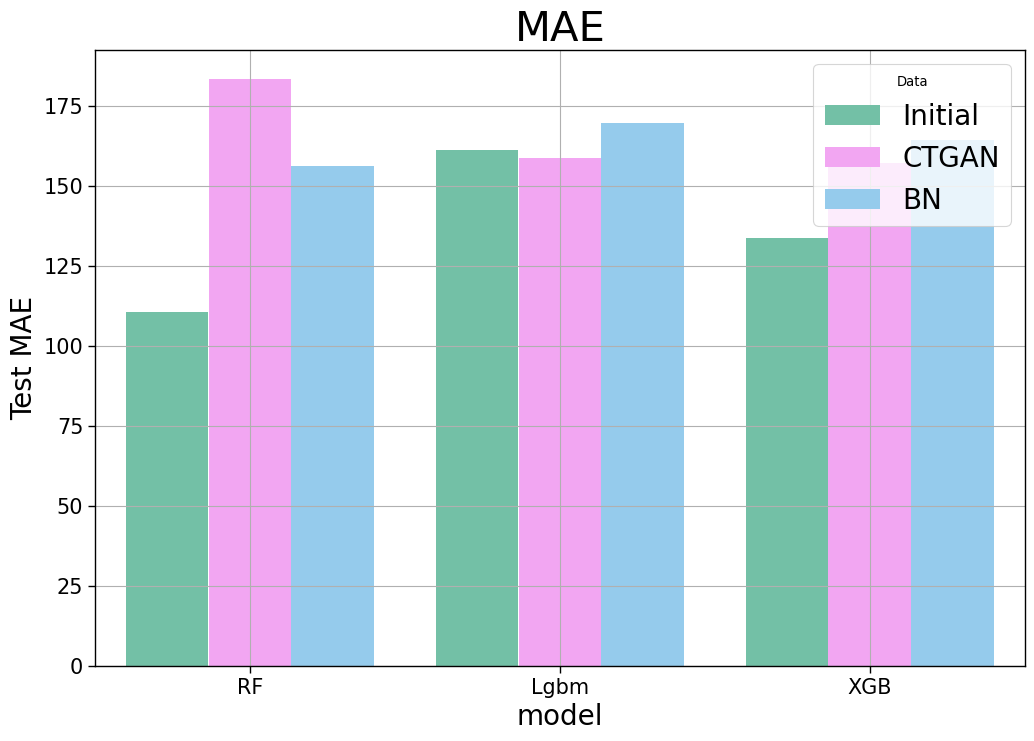

In [255]:
df = pd.concat([df_rfreg, df_lgbmreg, df_xgbreg])
df.index.rename('Data', inplace=True)
df.reset_index(inplace=True)

pastel_colors = ['#66CDAA', '#FF99FF', '#87CEFA']

fig = plt.figure(figsize=(12, 8))
sns.barplot(x='model', y='Test MAE', hue='Data', data=df, palette=pastel_colors)
plt.title('MAE')
plt.grid()
plt.show()

In [210]:
cleared_synthetic_samples_df = remove_outliers(synthetic_samples_df)
cleared_synthetic_samples_df.shape

Index(['host_response_time', 'host_acceptance_rate', 'neighbourhood_cleansed',
       'reviews_per_month', 'number_of_reviews', 'property_type', 'City',
       'beds', 'bedrooms', 'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_location',
       'review_scores_communication', 'host_is_superhost', 'accommodates',
       'price'],
      dtype='object')


(10000, 17)

In [212]:
# Декодируем обратно категориальные переменные
for column, le in label_encoders.items():
    synthetic_samples_df[column] = le.inverse_transform(synthetic_samples_df[column])

synthetic_samples_df

,host_response_time,host_acceptance_rate,neighbourhood_cleansed,reviews_per_month,number_of_reviews,property_type,City,beds,bedrooms,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_location,review_scores_communication,host_is_superhost,accommodates,price
0,within an hour,100,Long Beach,2.31,92,Entire guesthouse,los-angeles,1,1,4.93,4.98,4.88,4.92,5.00,1,3,150.0
1,within an hour,99,Mission Bay,2.82,150,Entire guesthouse,san-diego,3,1,4.91,4.94,4.91,4.19,4.95,0,6,405.0
2,within an hour,98,Hollywood,0.13,9,Entire rental unit,los-angeles,1,1,4.58,4.68,4.19,3.38,4.78,0,3,152.0
3,within an hour,100,San Jose,5.49,139,Entire home,santa-clara-county,2,1,4.84,4.85,4.80,4.92,4.89,1,5,263.0
4,within an hour,100,San Jose,2.25,207,Private room in home,santa-clara-county,1,4,5.00,4.95,4.95,4.97,4.95,1,1,55.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26995,within a few hours,35,Venice,0.37,8,Private room in home,los-angeles,1,1,4.50,4.83,4.17,4.13,4.50,0,2,80.0
26996,within a few hours,100,San Jose,0.34,20,Entire home,santa-clara-county,9,1,4.84,4.95,4.97,4.90,4.95,0,12,159.0
26997,within an hour,89,Hollywood,1.00,0,Private room in rental unit,los-angeles,1,1,5.00,5.00,5.00,5.00,5.00,0,2,48.0
26998,within an hour,97,San Jose,1.09,33,Entire guesthouse,santa-clara-county,2,1,4.82,4.94,4.59,4.76,4.94,1,4,155.0


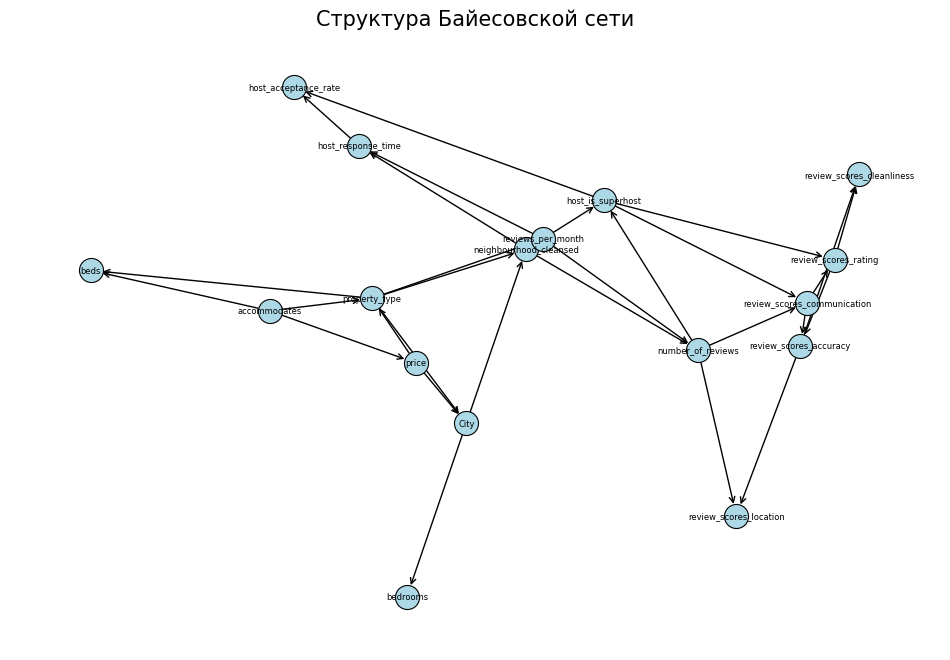

In [214]:
# Получаем структуру графа из модели
edges = best_model.edges()
G = nx.DiGraph()
G.add_edges_from(edges)

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G)
nx.draw_networkx_nodes(G, pos, node_size=300, node_color='lightblue', edgecolors='black')
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=10)
nx.draw_networkx_labels(G, pos, font_size=6, font_family='sans-serif')

plt.title("Структура Байесовской сети", fontsize=15)
plt.axis('off')
plt.show()

In [216]:
synthetic_samples_df.to_csv('./synthetic data/synthetic_data_BN_reg_test.csv', index=False)

In [ ]:
DIFFPRIVLIB

In [262]:
!conda install -y diffprivlib

Retrieving notices: done
Channels:
 - defaults
 - conda-forge
 - pytorch-nightly
Platform: osx-arm64
Solving environment: done

## Package Plan ##

  environment location: /Users/nik/bmstu/diff-privacy/anaconda/anaconda3

  added / updated specs:
    - diffprivlib


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    diffprivlib-0.6.4          |     pyhd8ed1ab_0          92 KB  conda-forge
    ------------------------------------------------------------
                                           Total:          92 KB

The following NEW packages will be INSTALLED:

  diffprivlib        conda-forge/noarch::diffprivlib-0.6.4-pyhd8ed1ab_0 



                                                                                
Preparing transaction: done
Verifying transaction: done
Executing transaction: done


In [274]:
from diffprivlib.models import GaussianNB

clf = GaussianNB()
clf.fit(X_train, y_train)

ValueError: could not convert string to float: 'Unknown'

In [270]:
y_train

346       80.0
13028    150.0
8821     756.0
25676    143.0
7534     125.0
         ...  
29802    420.0
5390     141.0
860      150.0
15795     99.0
23654    144.0
Name: price, Length: 27000, dtype: float64

 # Сравнение реальных и синтетических данных для задачи регрессии

In [219]:
import pandas as pd

synthetic_data_ctgan = pd.read_csv('./synthetic data/synthetic_data_CTGAN_reg_test.csv')
synthetic_data_bamt = pd.read_csv('./synthetic data/synthetic_data_BN_reg_test.csv')
metadata = SingleTableMetadata.load_from_json('./data/metadata_reg.json')

synthetic_data_ctgan.shape, synthetic_data_bamt.shape 

((27000, 17), (27000, 17))

In [221]:
synthetic_data_bamt.dtypes

host_response_time              object
host_acceptance_rate             int64
neighbourhood_cleansed          object
reviews_per_month              float64
number_of_reviews                int64
property_type                   object
City                            object
beds                             int64
bedrooms                         int64
review_scores_rating           float64
review_scores_accuracy         float64
review_scores_cleanliness      float64
review_scores_location         float64
review_scores_communication    float64
host_is_superhost                int64
accommodates                     int64
price                          float64
dtype: object

In [223]:
synthetic_data_ctgan.dtypes

host_response_time              object
neighbourhood_cleansed          object
property_type                   object
City                            object
price                          float64
review_scores_rating           float64
review_scores_accuracy         float64
review_scores_cleanliness      float64
review_scores_location         float64
review_scores_communication    float64
reviews_per_month              float64
bedrooms                         int64
accommodates                     int64
beds                             int64
host_acceptance_rate             int64
host_is_superhost                int64
number_of_reviews                int64
dtype: object

In [225]:
real_data.dtypes

host_response_time              object
neighbourhood_cleansed          object
property_type                   object
City                            object
review_scores_rating           float64
review_scores_accuracy         float64
review_scores_cleanliness      float64
review_scores_location         float64
review_scores_communication    float64
reviews_per_month              float64
bedrooms                         int64
accommodates                     int64
beds                             int64
host_acceptance_rate             int64
host_is_superhost                int64
number_of_reviews                int64
price                          float64
dtype: object

In [227]:
from sdv.evaluation.single_table import run_diagnostic

diagnostic_ctgan = run_diagnostic(
    real_data=real_data,
    synthetic_data=synthetic_data_ctgan,
    metadata=metadata
)

diagnostic_bamt = run_diagnostic(
    real_data=real_data,
    synthetic_data=synthetic_data_bamt,
    metadata=metadata
)

Generating report ...

(1/2) Evaluating Data Validity: |█████████████| 17/17 [00:00<00:00, 417.43it/s]|
Data Validity Score: 100.0%

(2/2) Evaluating Data Structure: |█████████████| 1/1 [00:00<00:00, 1053.85it/s]|
Data Structure Score: 100.0%

Overall Score (Average): 100.0%

Generating report ...

(1/2) Evaluating Data Validity: |█████████████| 17/17 [00:00<00:00, 698.43it/s]|
Data Validity Score: 100.0%

(2/2) Evaluating Data Structure: |█████████████| 1/1 [00:00<00:00, 1023.25it/s]|
Data Structure Score: 100.0%

Overall Score (Average): 100.0%



In [229]:
diagnostic_ctgan.get_details(property_name='Data Validity')

,Column,Metric,Score
0,host_response_time,CategoryAdherence,1.0
1,neighbourhood_cleansed,CategoryAdherence,1.0
2,property_type,CategoryAdherence,1.0
3,City,CategoryAdherence,1.0
4,price,BoundaryAdherence,1.0
5,review_scores_rating,BoundaryAdherence,1.0
6,review_scores_accuracy,BoundaryAdherence,1.0
7,review_scores_cleanliness,BoundaryAdherence,1.0
8,review_scores_location,BoundaryAdherence,1.0
9,review_scores_communication,BoundaryAdherence,1.0


In [231]:
diagnostic_bamt.get_details(property_name='Data Validity')

,Column,Metric,Score
0,host_response_time,CategoryAdherence,1.0
1,neighbourhood_cleansed,CategoryAdherence,1.0
2,property_type,CategoryAdherence,1.0
3,City,CategoryAdherence,1.0
4,price,BoundaryAdherence,1.0
5,review_scores_rating,BoundaryAdherence,1.0
6,review_scores_accuracy,BoundaryAdherence,1.0
7,review_scores_cleanliness,BoundaryAdherence,1.0
8,review_scores_location,BoundaryAdherence,1.0
9,review_scores_communication,BoundaryAdherence,1.0


In [233]:
from sdv.evaluation.single_table import evaluate_quality

quality_report_ctgan = evaluate_quality(
    real_data=real_data,
    synthetic_data=synthetic_data_ctgan,
    metadata=metadata
)

quality_report_bamt = evaluate_quality(
    real_data=real_data,
    synthetic_data=synthetic_data_bamt,
    metadata=metadata
)

Generating report ...

(1/2) Evaluating Column Shapes: |██████████████| 17/17 [00:00<00:00, 82.09it/s]|
Column Shapes Score: 90.07%

(2/2) Evaluating Column Pair Trends: |██████| 136/136 [00:00<00:00, 309.62it/s]|
Column Pair Trends Score: 83.48%

Overall Score (Average): 86.78%

Generating report ...

(1/2) Evaluating Column Shapes: |█████████████| 17/17 [00:00<00:00, 141.04it/s]|
Column Shapes Score: 92.97%

(2/2) Evaluating Column Pair Trends: |██████| 136/136 [00:00<00:00, 315.90it/s]|
Column Pair Trends Score: 90.76%

Overall Score (Average): 91.86%



In [235]:
ctgan_report = quality_report_ctgan.get_details('Column Shapes')
ctgan_report.rename(columns={'Score': 'CTGAN_score'}, inplace=True)

bamt_report = quality_report_bamt.get_details('Column Shapes')
bamt_report.rename(columns={'Score': 'BN_score'}, inplace=True)

adj_report = pd.concat([ctgan_report, bamt_report.BN_score], axis=1)
adj_report

,Column,Metric,CTGAN_score,BN_score
0,host_response_time,TVComplement,0.820111,0.974519
1,neighbourhood_cleansed,TVComplement,0.898741,0.871667
2,property_type,TVComplement,0.870222,0.726741
3,City,TVComplement,0.917444,0.862815
4,price,KSComplement,0.924148,0.820148
5,review_scores_rating,KSComplement,0.926259,0.987519
6,review_scores_accuracy,KSComplement,0.845630,0.990333
7,review_scores_cleanliness,KSComplement,0.872704,0.989593
8,review_scores_location,KSComplement,0.927741,0.802074
9,review_scores_communication,KSComplement,0.934222,0.987333


In [237]:
plot_cols = {'property_type': ['review_scores_rating'],
             'City': ['review_scores_location']}

sns.set_context("paper", rc={"axes.titlesize":30,"axes.labelsize":20, "legend.fontsize": 20, "xtick.labelsize":15, "ytick.labelsize":15})
for cat_name in plot_cols:
  cats = synthetic_data_ctgan[cat_name].value_counts().index[:3]
  for col in plot_cols[cat_name]:
    fig, ax= plt.subplots(1, len(cats), figsize=(10*len(cats), 10),)
    for i, cat in enumerate(cats):
      sns.distplot(X_train[X_train[cat_name]==cat][col], ax=ax[i], label='Real', color=REAL_COLOR)
      sns.distplot(synthetic_data_ctgan[synthetic_data_ctgan[cat_name]==cat][col], ax=ax[i], label='Fake CTGAN', color=CTGAN_COLOR)
      ax[i].grid(True)
      ax[i].set_title(f'{col} {cat}')
      ax[i].legend(loc=0)
      ax[i].set_ylim(0, 4)
      ax[i].set_xlim(3, 5)

In [239]:
plot_cols = {'property_type': ['review_scores_rating'],
             'City': ['review_scores_location']}

sns.set_context("paper", rc={"axes.titlesize":30,"axes.labelsize":20, "legend.fontsize": 20, "xtick.labelsize":15, "ytick.labelsize":15})
for cat_name in plot_cols:
  cats = synthetic_data_bamt[cat_name].value_counts().index[:3]
  for col in plot_cols[cat_name]:
    fig, ax= plt.subplots(1, len(cats), figsize=(10*len(cats), 10),)
    for i, cat in enumerate(cats):
      sns.distplot(X_train[X_train[cat_name]==cat][col], ax=ax[i], label='Real', color=REAL_COLOR)
      sns.distplot(synthetic_data_bamt[synthetic_data_bamt[cat_name]==cat][col], ax=ax[i], label='Fake BN', color=BAMT_COLOR)
      ax[i].grid(True)
      ax[i].set_title(f'{col} {cat}')
      ax[i].legend(loc=0)
      ax[i].set_ylim(0, 4)
      ax[i].set_xlim(3, 5)

In [241]:
cont_data = real_data.select_dtypes(['float']).columns.drop(['price']).to_list()

cont_data.append('number_of_reviews')
cont_data.append('host_acceptance_rate')

cols = 2

rows = max (1 , len(cont_data) // cols)

sns.set_context("paper", rc={"axes.titlesize":30,"axes.labelsize":20, "legend.fontsize": 20, "xtick.labelsize":1, "ytick.labelsize":15})

fig, ax= plt.subplots(rows, cols, figsize=(20, 30))
axes = ax.flatten()

for i, col in enumerate(cont_data):
    sns.distplot(real_data[col], ax=axes[i], label='Real', color=REAL_COLOR, kde=True)
    sns.distplot(synthetic_data_ctgan[col], ax=axes[i], label='Fake CTGAN', color=CTGAN_COLOR, kde=True)
    sns.distplot(synthetic_data_bamt[col], ax=axes[i], label='Fake BN', color=BAMT_COLOR, kde=True)

    axes[i].grid(True)
    axes[i].legend(loc=0)
    axes[i].set_xlim(np.percentile(synthetic_data_ctgan[col], 5), np.percentile(synthetic_data_ctgan[col], 99))
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')
    axes[i].set_title(f'Distribution of {col}')

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should

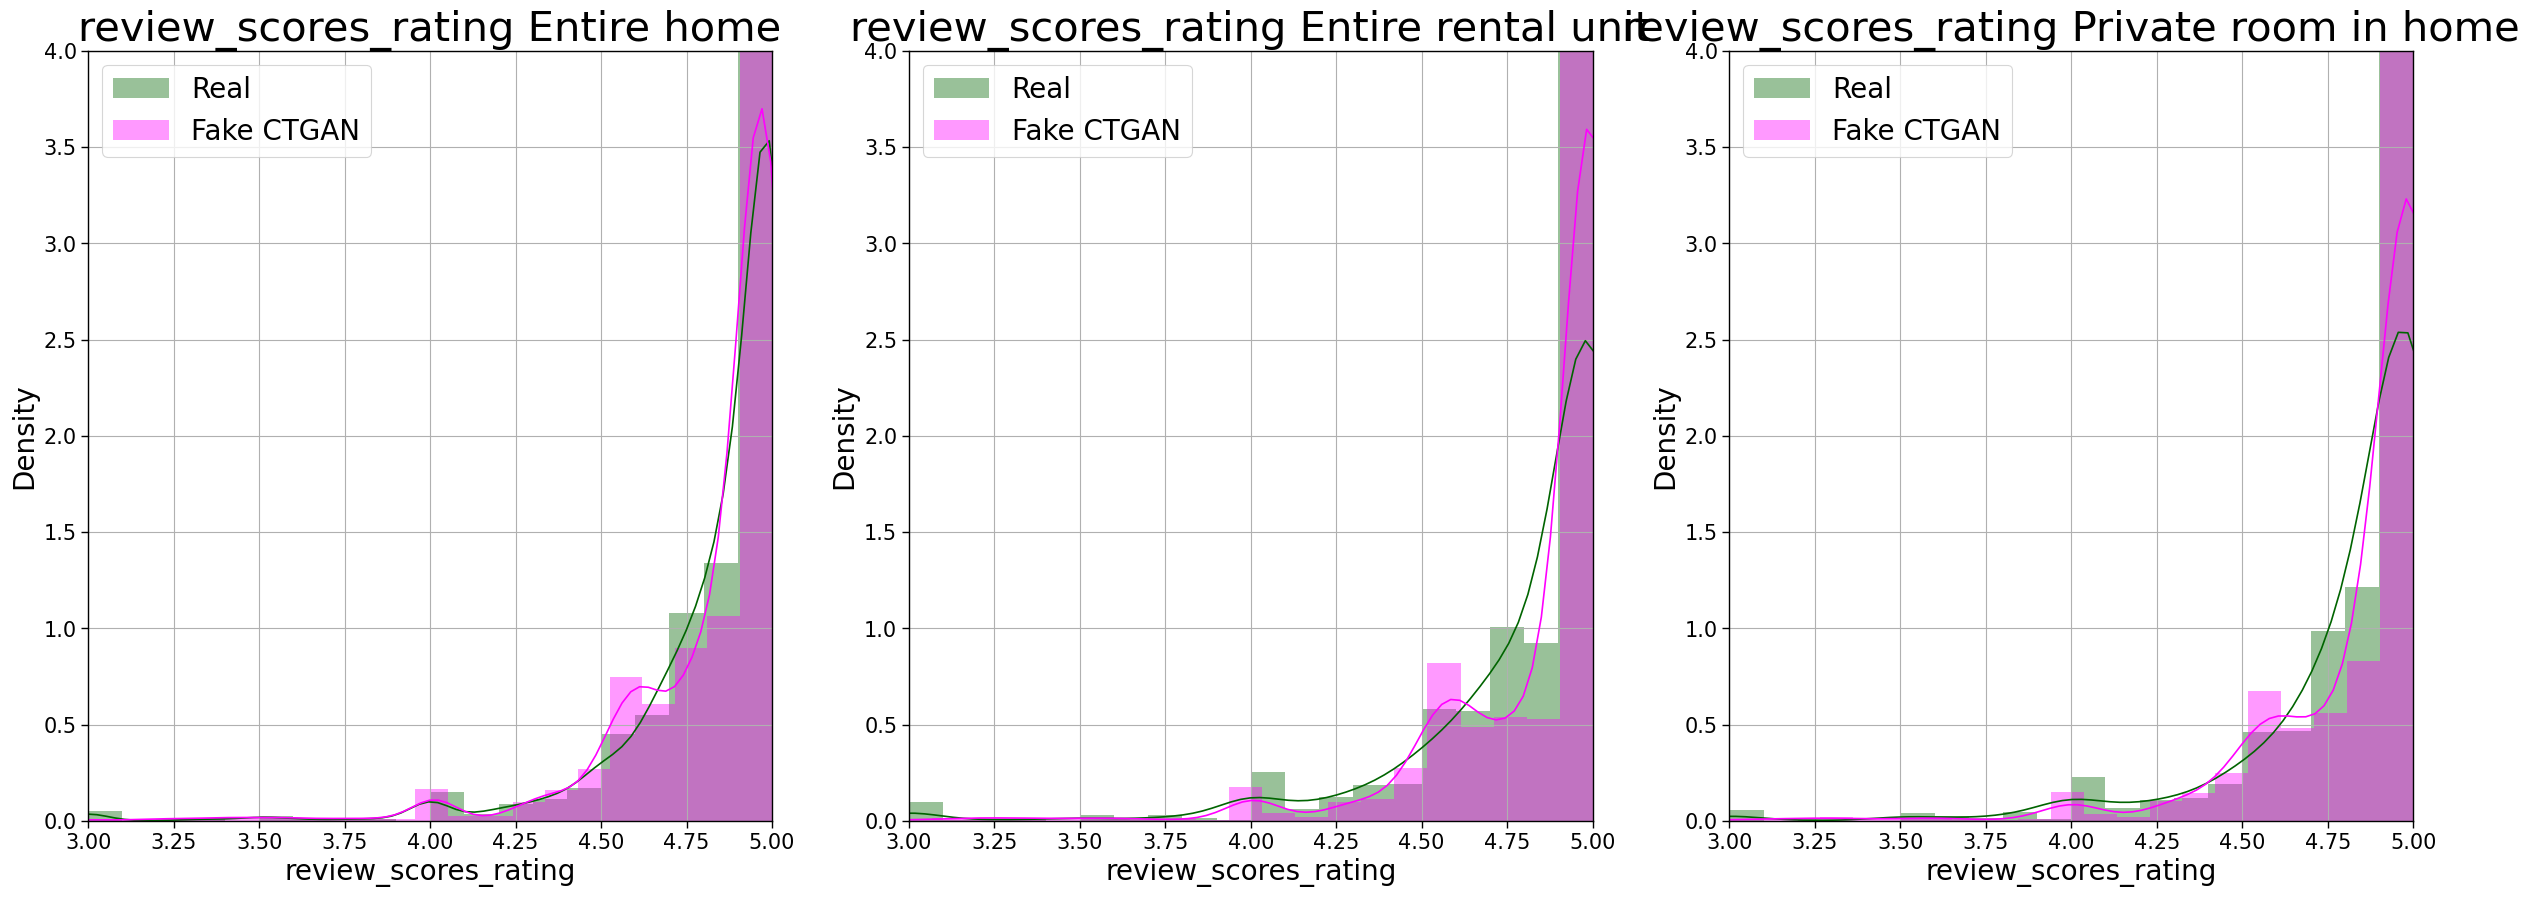

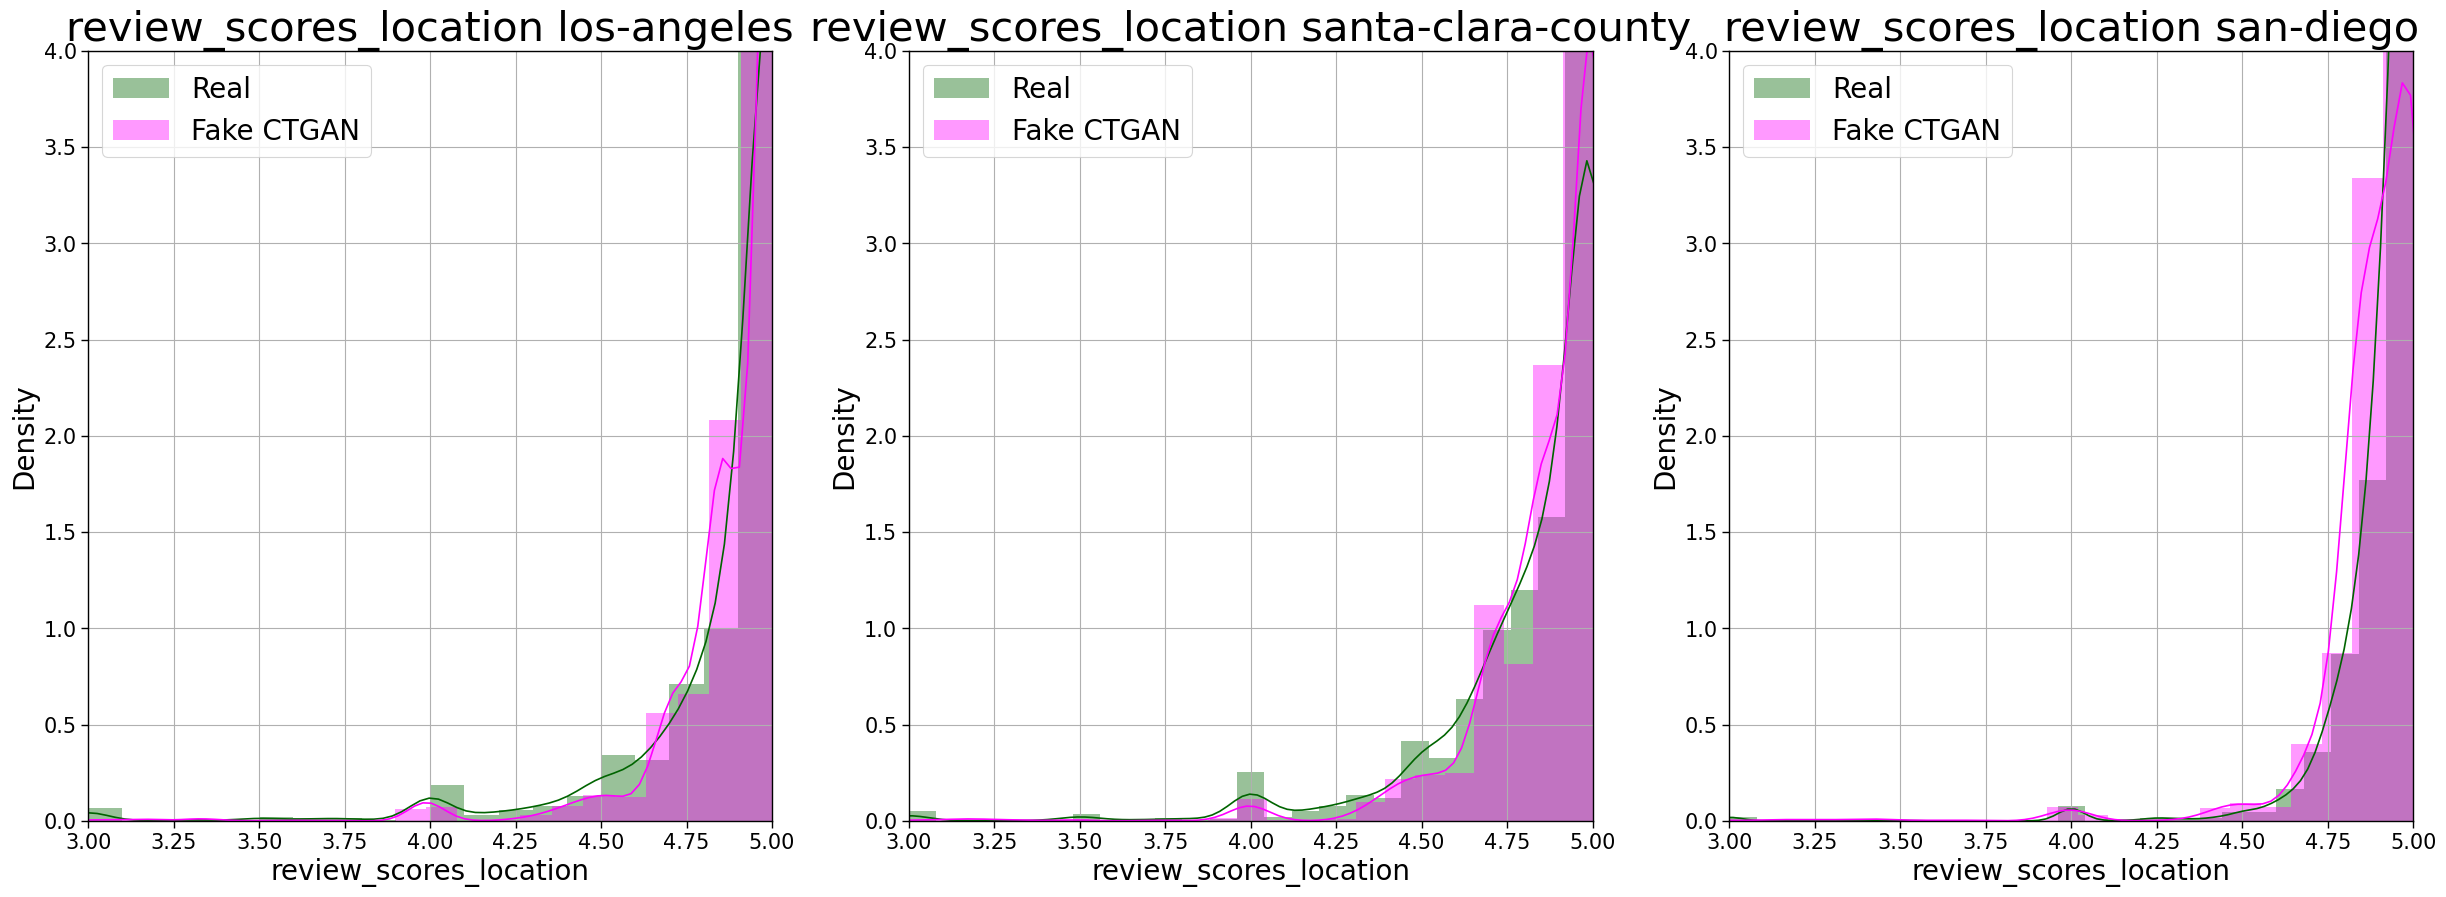

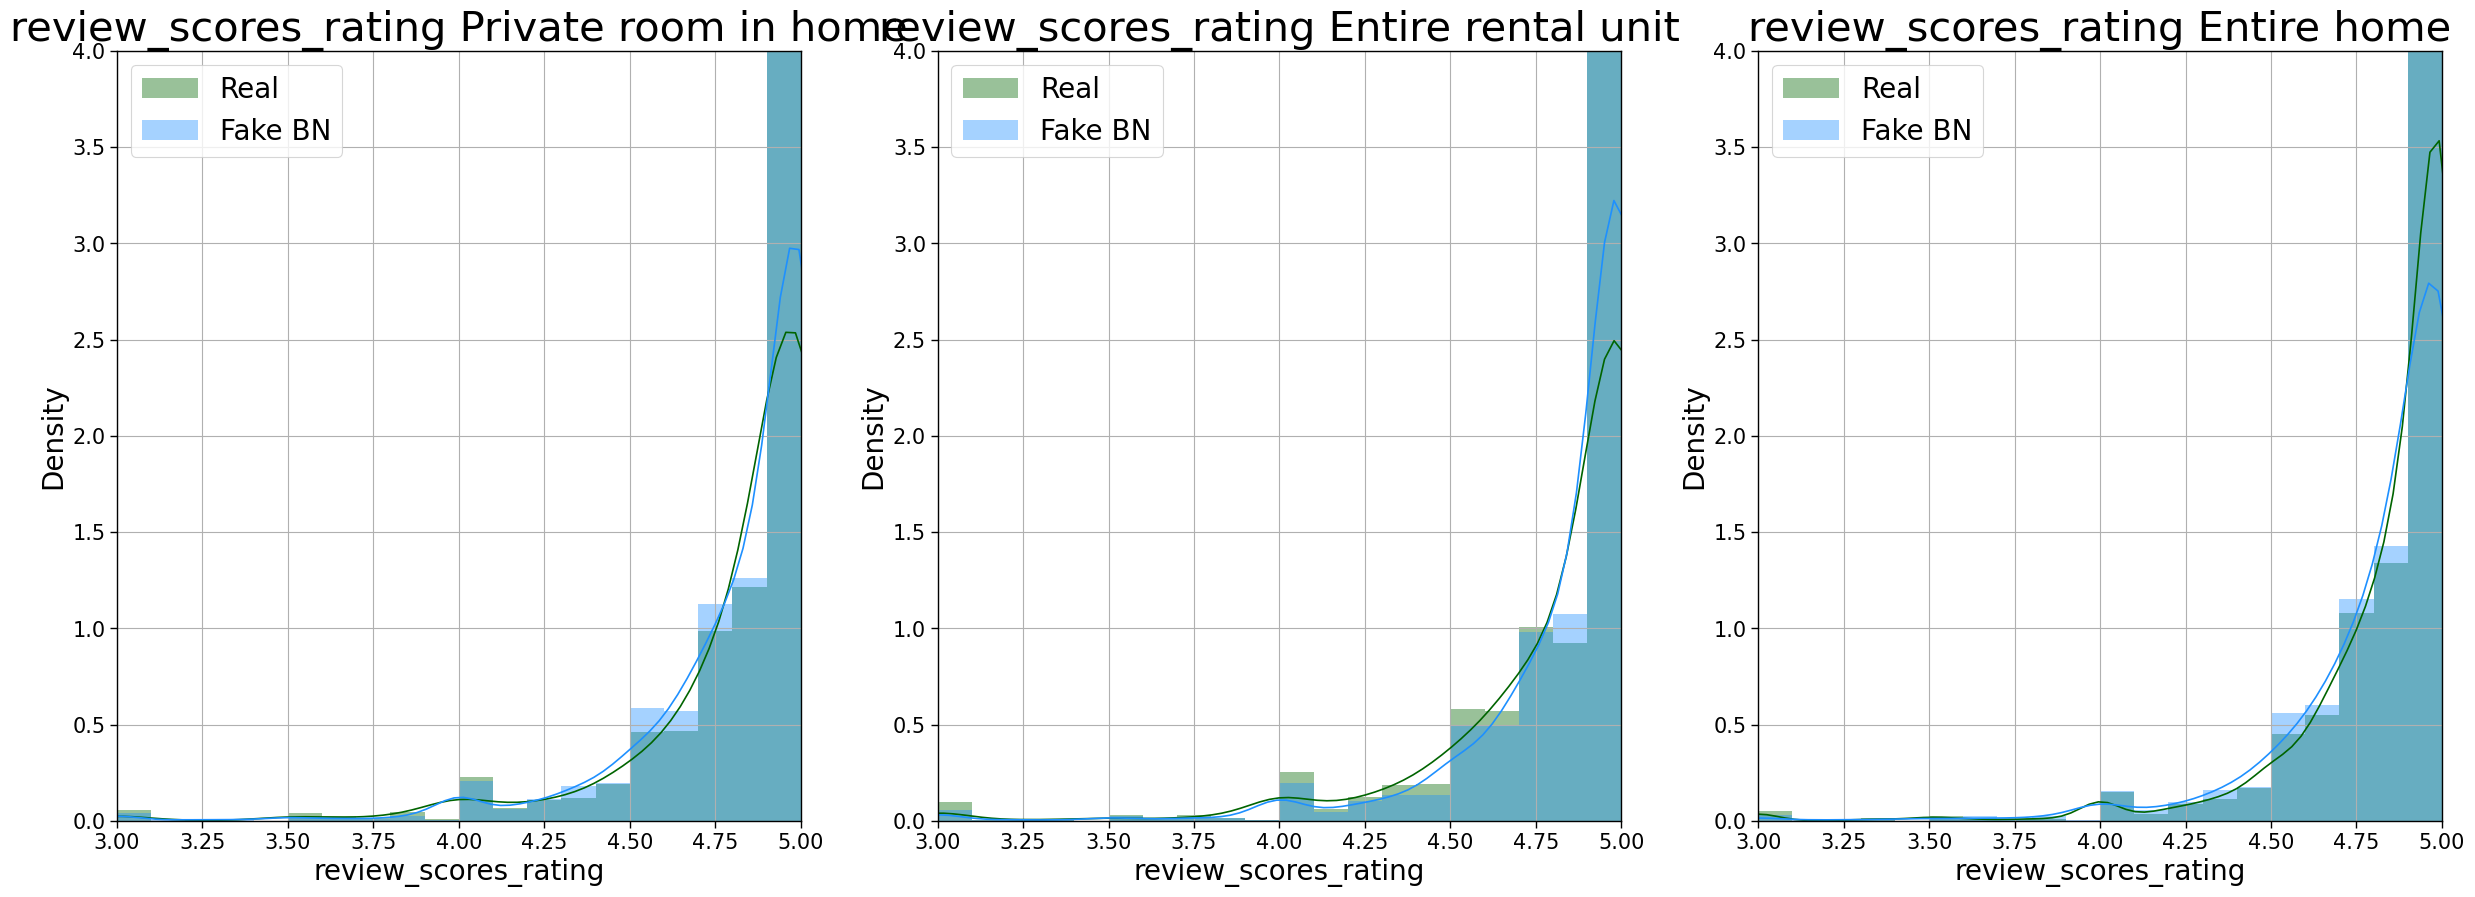

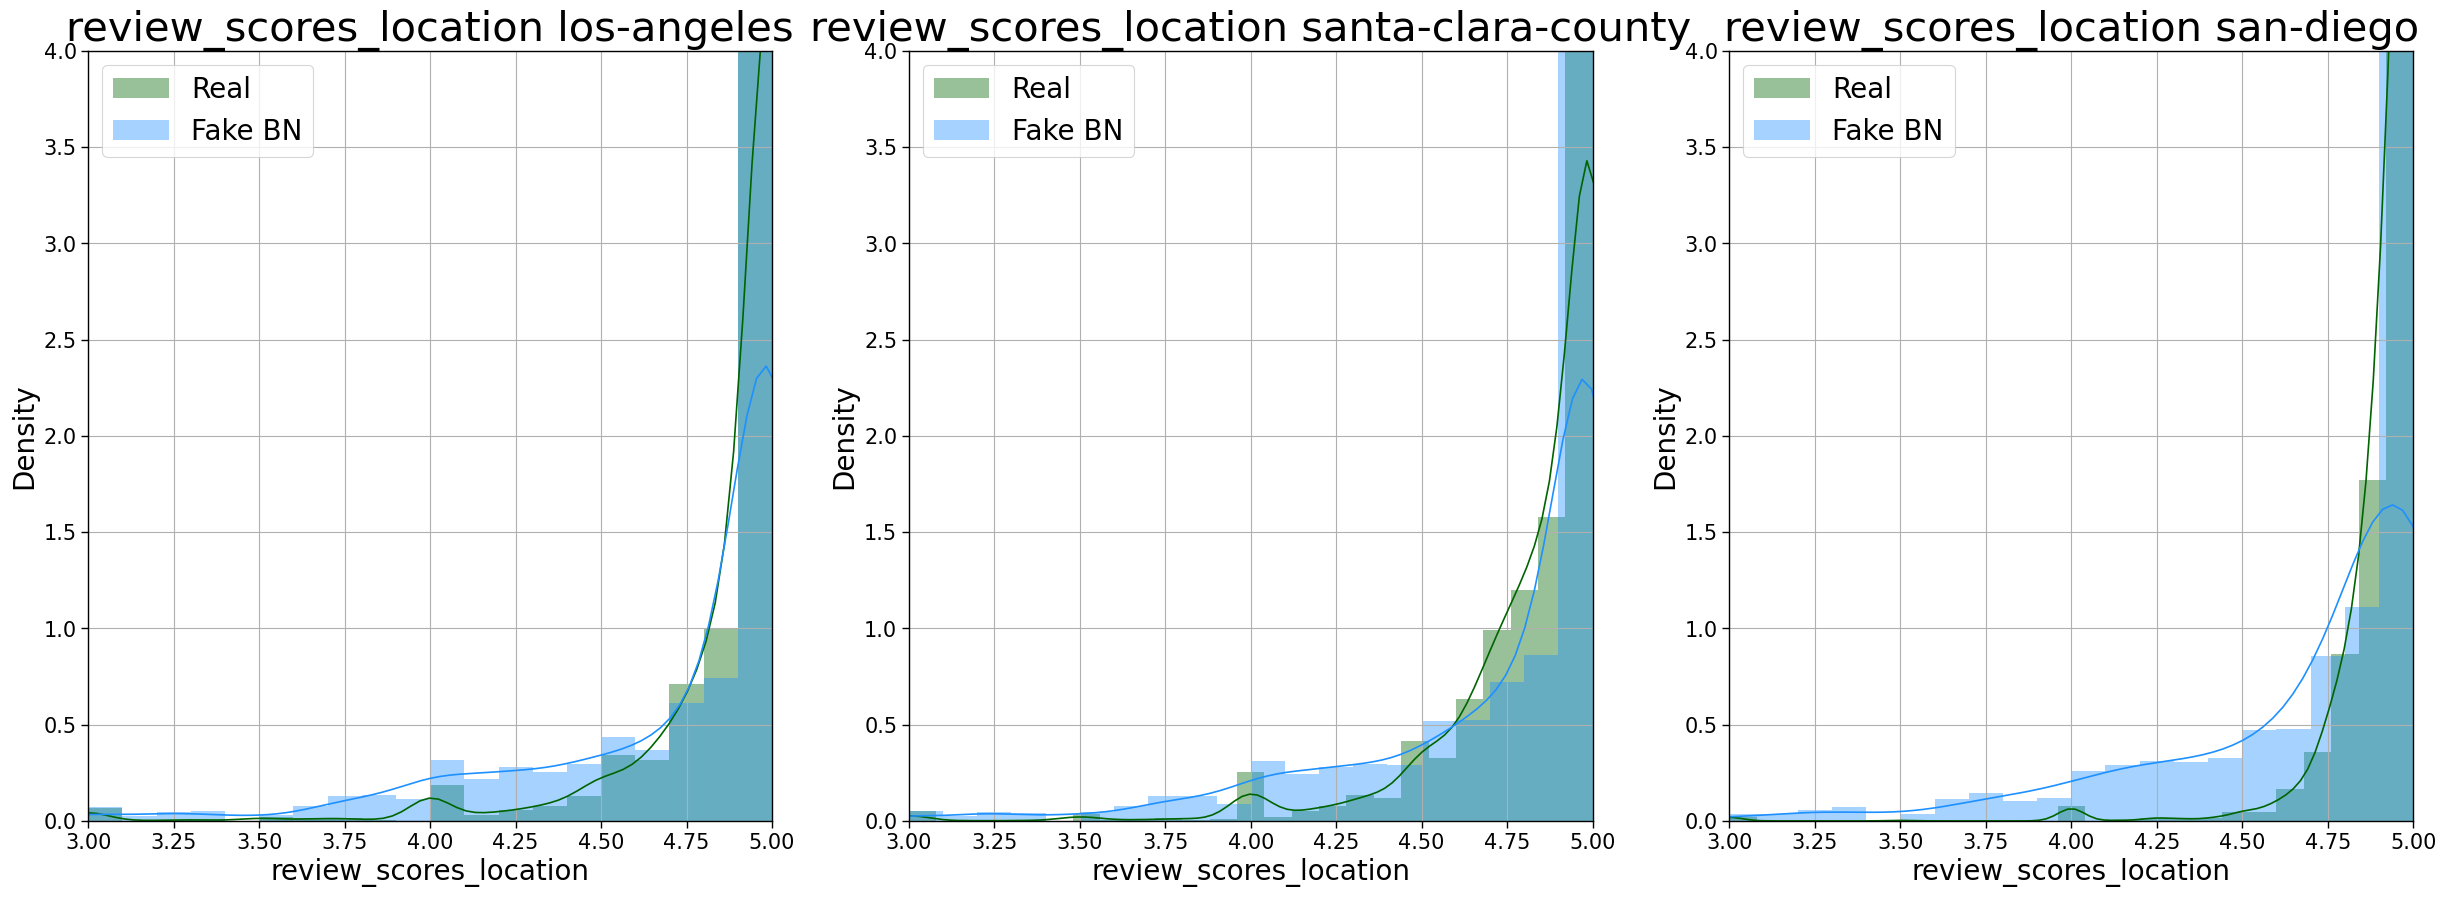

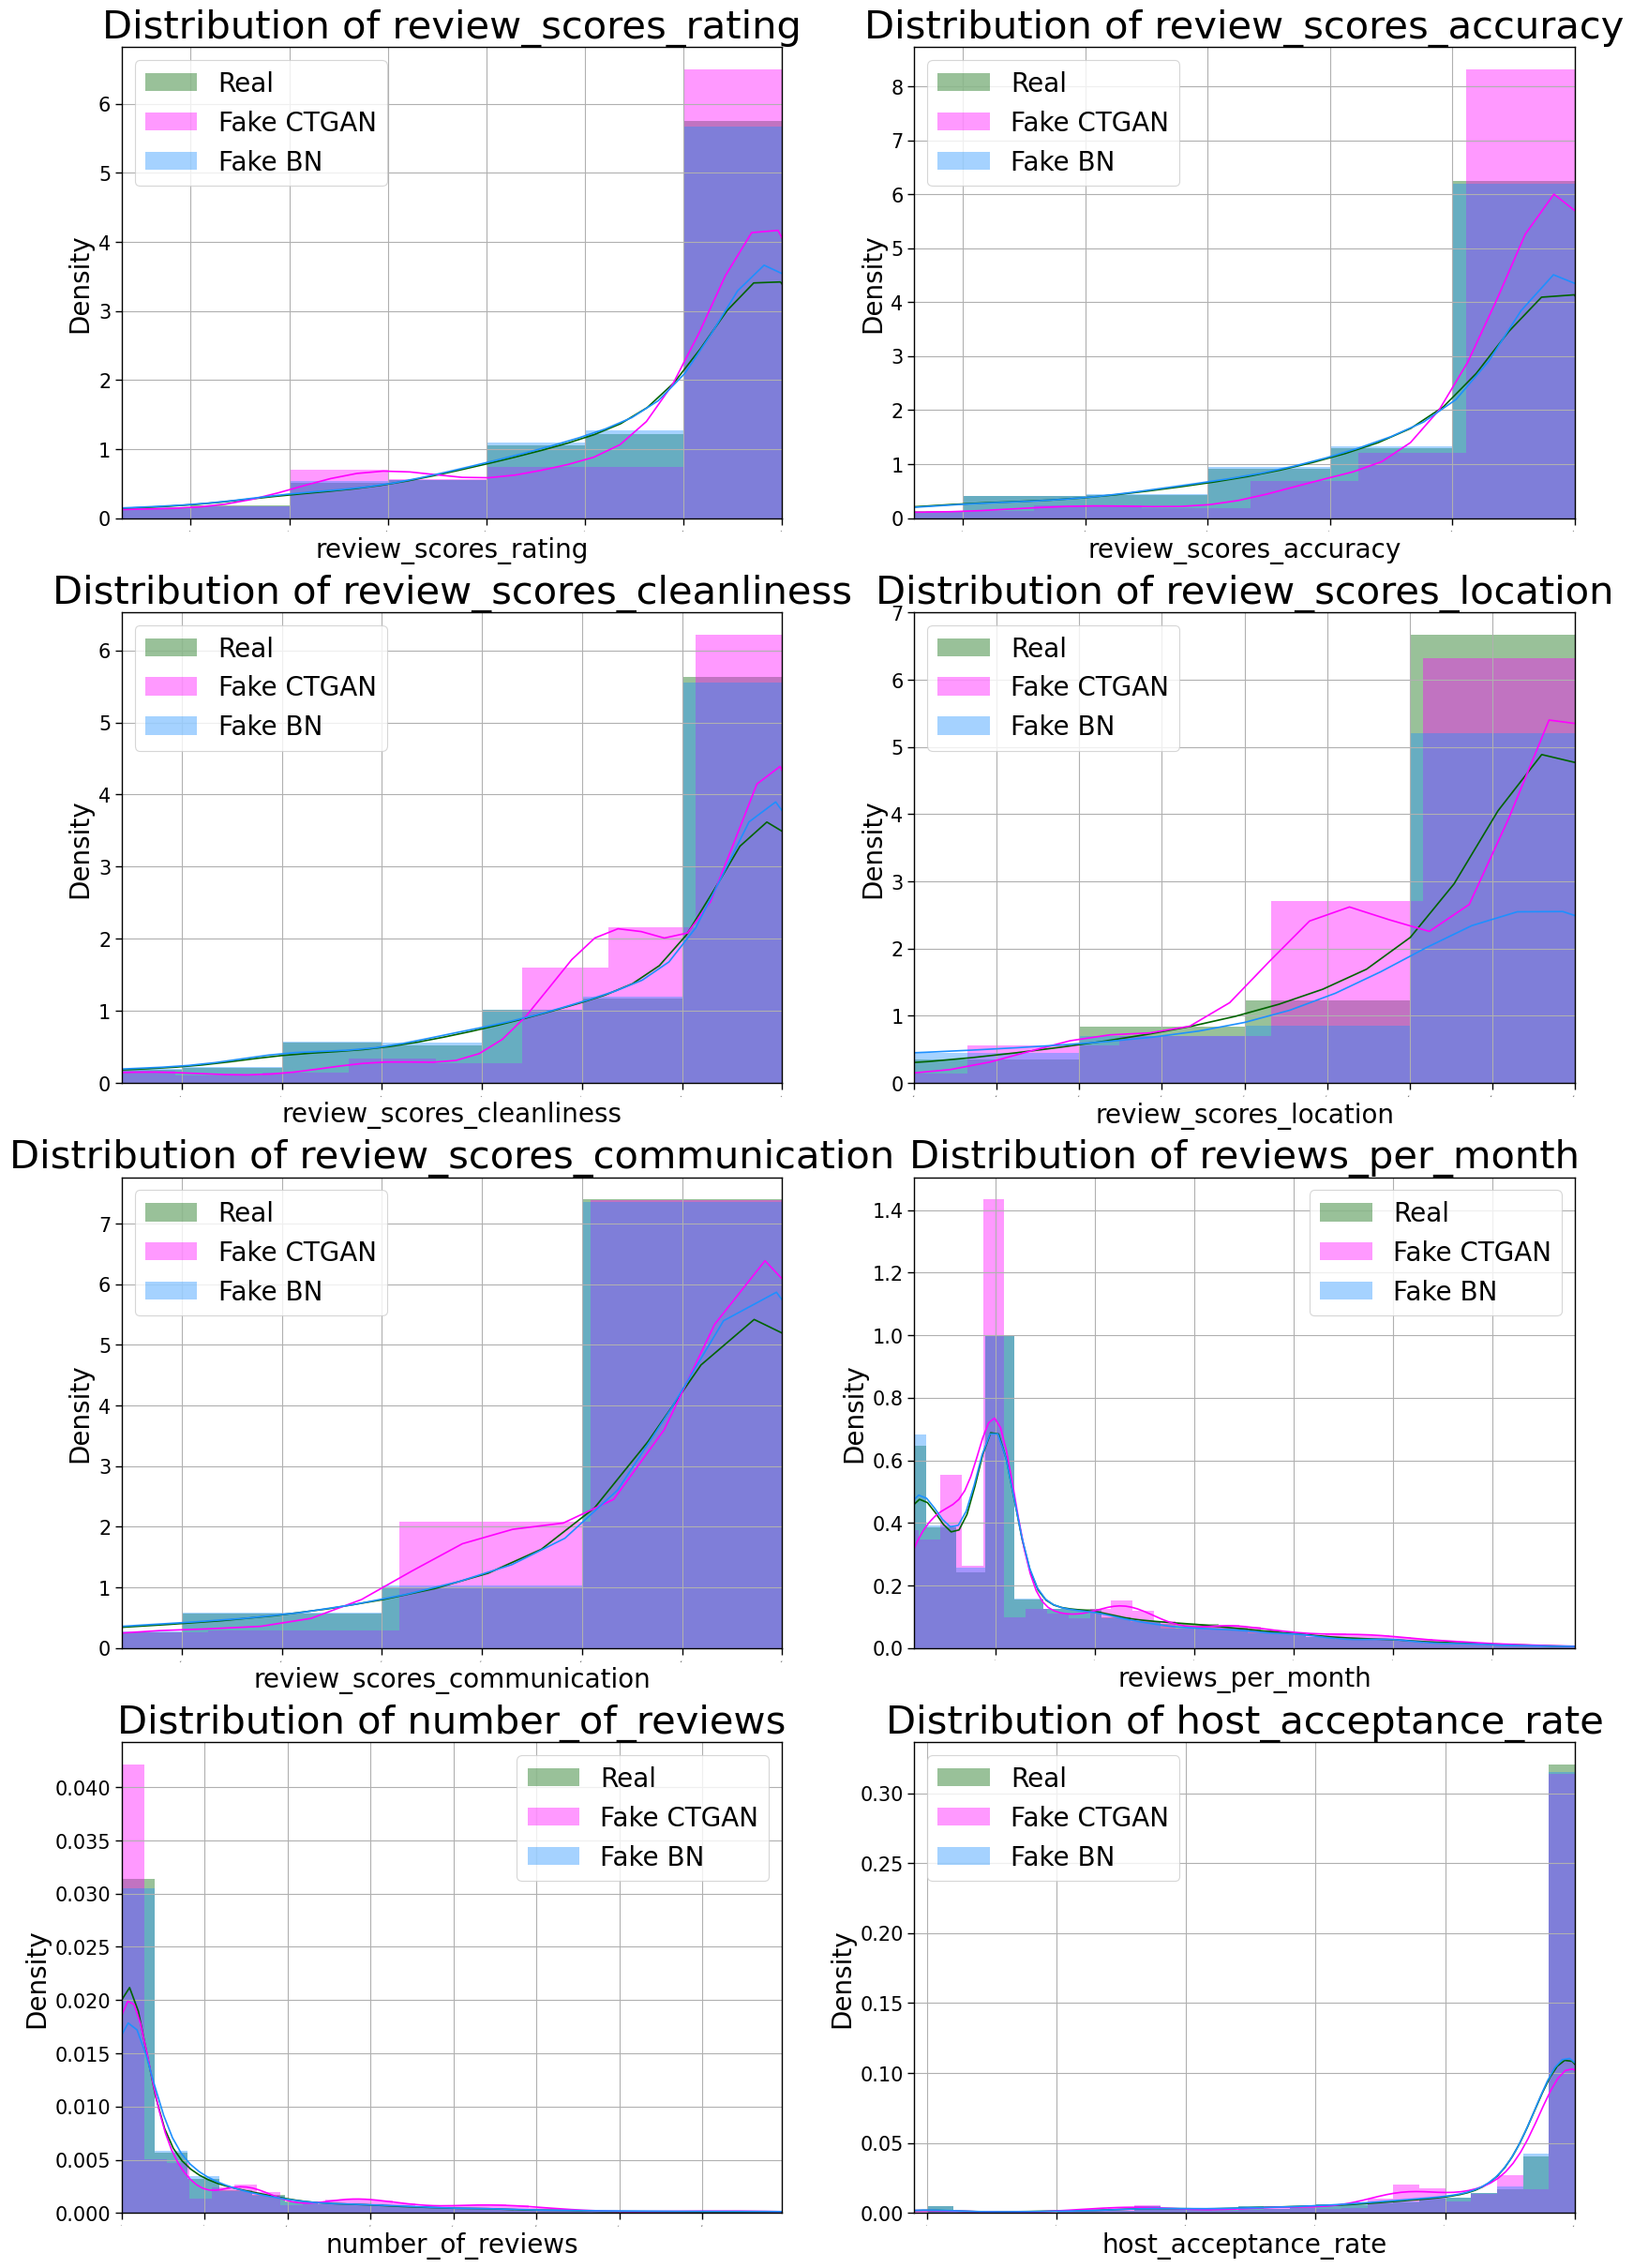

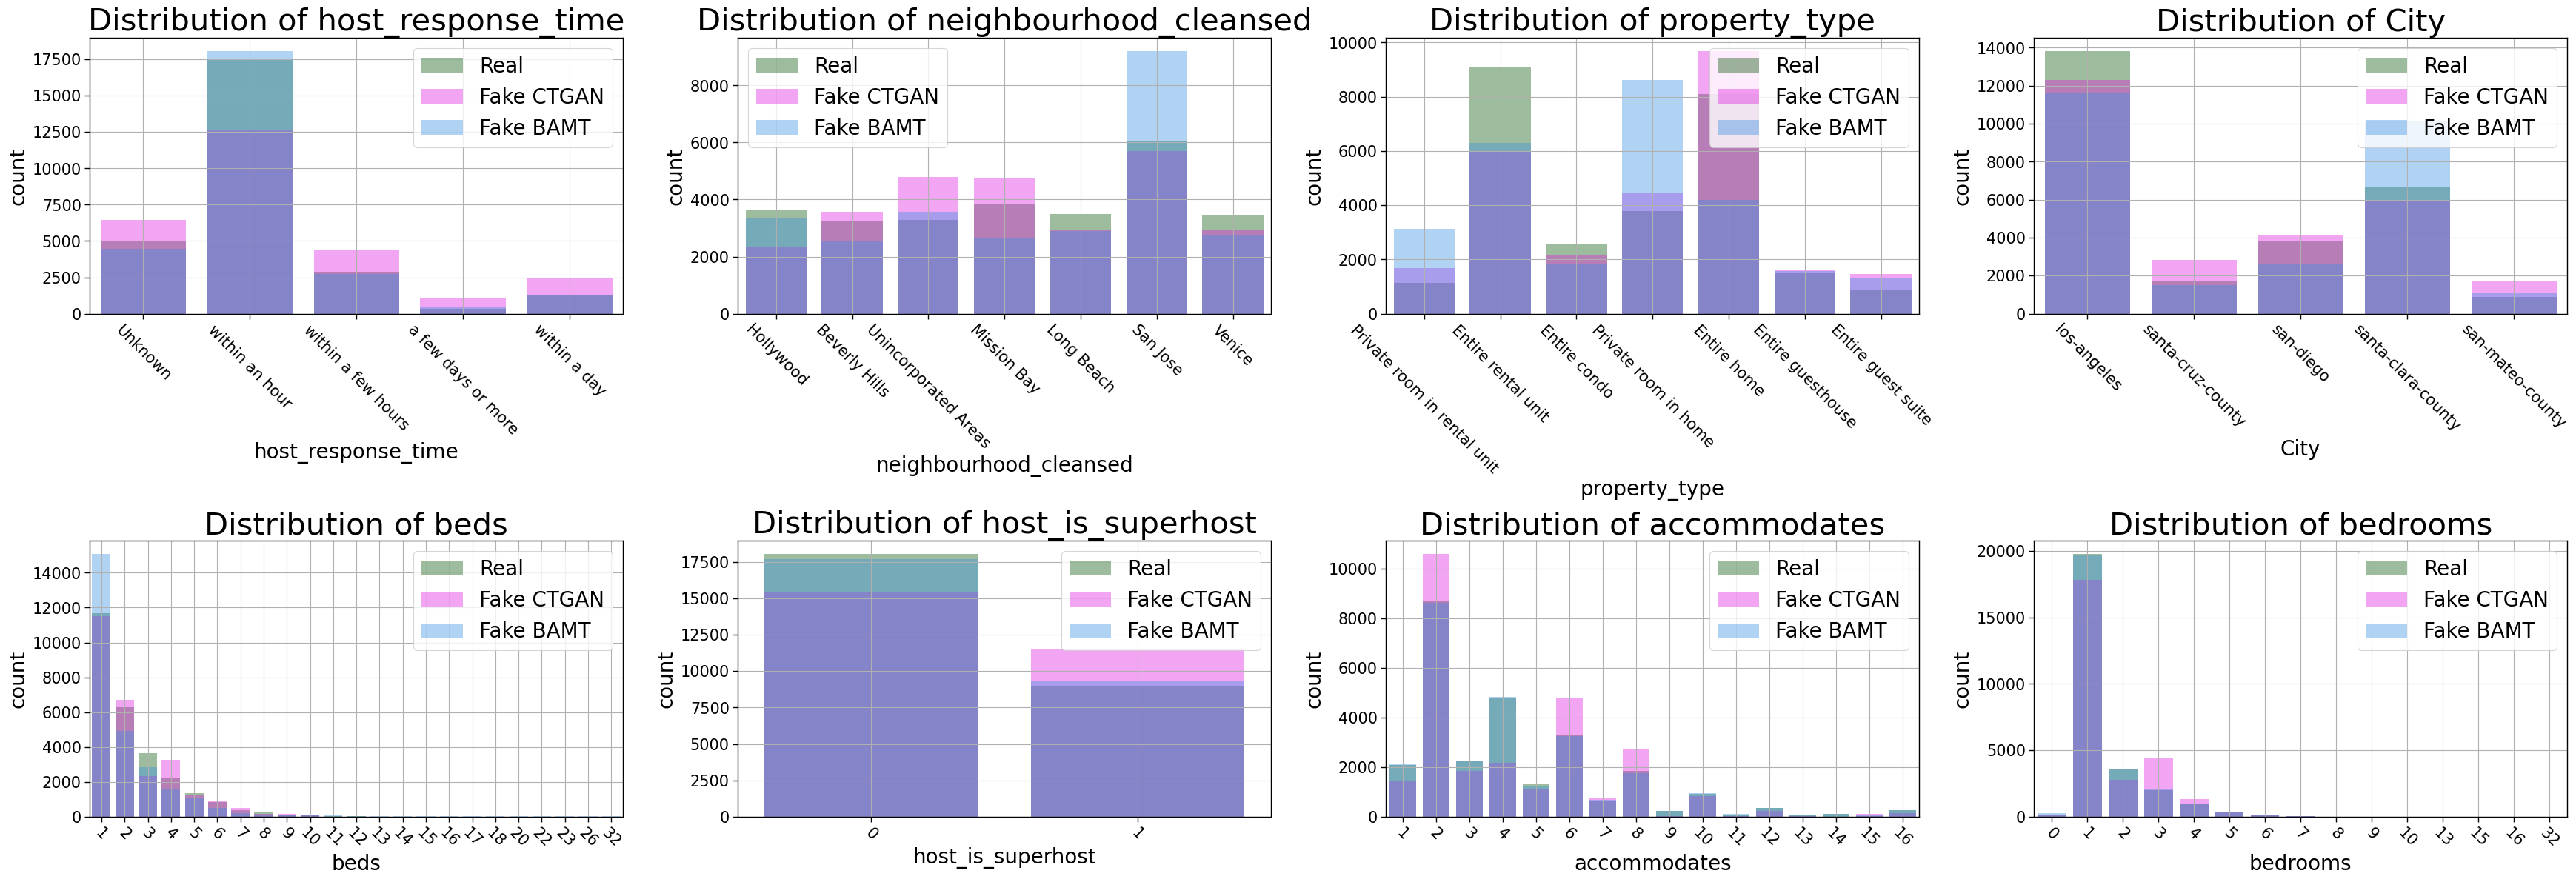

In [242]:
cols = 4
rows = (len(cat_features) + cols - 1) // cols + 1

sns.set_context("paper", rc={"axes.titlesize":30, "axes.labelsize":20, "legend.fontsize":20, "xtick.labelsize":15, "ytick.labelsize":15})

fig, ax = plt.subplots(rows, cols, figsize=(35, 6 * rows))
axes = ax.flatten()

disc_features = cat_features.copy()
disc_features.append('beds')
disc_features.append('host_is_superhost')
disc_features.append('accommodates')
disc_features.append('bedrooms')


for i, col in enumerate(disc_features):
    sns.countplot(x=real_data[col], ax=axes[i], label='Real', color=REAL_COLOR, alpha=0.4)
    sns.countplot(x=synthetic_data_ctgan[col], ax=axes[i], label='Fake CTGAN', color=CTGAN_COLOR, alpha=0.4)
    sns.countplot(x=synthetic_data_bamt[col], ax=axes[i], label='Fake BAMT', color=BAMT_COLOR, alpha=0.4)

    axes[i].grid(True)
    axes[i].legend(loc=0)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].tick_params(axis='x', rotation=-45)

plt.tight_layout()
plt.show()

# Регрессия. Предсказывание стоимости апартаментов

In [246]:
RFL_pipe = Pipeline([
    ('encoding', ce.OrdinalEncoder(
       encoding_method='ordered', variables=cat_features)),
    ('scaler', StandardScaler()),
    ('RF', RandomForestRegressor())
    ])

In [248]:
for col in cat_features:
    synthetic_data_bamt[col] = synthetic_data_bamt[col].astype('category')
    synthetic_data_ctgan[col] = synthetic_data_ctgan[col].astype('category')

In [250]:
right_pos_df_ctgan = pd.DataFrame()
right_pos_df_bn = pd.DataFrame()

for col in real_data.columns:
    right_pos_df_ctgan[col] = synthetic_data_ctgan[col]
    right_pos_df_bn[col] = synthetic_data_bamt[col]

synthetic_data_ctgan = right_pos_df_ctgan.copy()
synthetic_data_bamt = right_pos_df_bn.copy()

In [252]:
y_pred_test_initial_rfl = fit_predict(RFL_pipe, X_train.copy(), y_train, X_test, y_test, reg=True)
y_pred_test_ctgan_rfl = fit_predict(RFL_pipe, synthetic_data_ctgan.drop(['price'], axis=1), synthetic_data_ctgan['price'], X_test, y_test, reg=True)
y_pred_test_bamt_rfl = fit_predict(RFL_pipe, synthetic_data_bamt.drop(['price'], axis=1), synthetic_data_bamt['price'], X_test, y_test, reg=True)

y_pred_test_initial_lgbm = lgbm_predict(X_train.copy(), y_train, X_test, y_test, cat_features, reg=True)
y_pred_test_ctgan_lgbm = lgbm_predict(synthetic_data_ctgan.drop(['price'], axis=1), synthetic_data_ctgan['price'], X_test, y_test, cat_features, reg=True)
y_pred_test_bamt_lgbm = lgbm_predict(synthetic_data_bamt.drop(['price'], axis=1), synthetic_data_bamt['price'], X_test, y_test, cat_features, reg=True)

y_pred_test_initial_xgb = xgb_predict(X_train.copy(), y_train, X_test, y_test, cat_features)
y_pred_test_ctgan_xgb = xgb_predict(synthetic_data_ctgan.drop(['price'], axis=1), synthetic_data_ctgan['price'], X_test, y_test, cat_features)
y_pred_test_bamt_xgb = xgb_predict(synthetic_data_bamt.drop(['price'], axis=1), synthetic_data_bamt['price'], X_test, y_test, cat_features)

[LightGBM] [Warning] categorical_feature is set=host_response_time,neighbourhood_cleansed,property_type,City, categorical_column=0,1,2,3 will be ignored. Current value: categorical_feature=host_response_time,neighbourhood_cleansed,property_type,City
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000492 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1275
[LightGBM] [Info] Number of data points in the train set: 27000, number of used features: 16
[LightGBM] [Info] Start training from score 286.155889
[LightGBM] [Warning] categorical_feature is set=host_response_time,neighbourhood_cleansed,property_type,City, categorical_column=0,1,2,3 will be ignored. Current value: categorical_feature=host_response_time,neighbourhood_cleansed,property_type,City
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.0002

# Регрессия. Графики сравнения качества моделей


In [254]:
df_rfreg = pd.DataFrame(data=[mean_absolute_error(y_test,  y_pred_test_initial_rfl), mean_absolute_error(y_test,  y_pred_test_ctgan_rfl), mean_absolute_error(y_test,  y_pred_test_bamt_rfl)],
                     columns = ['Test MAE'],
                     index = ['Initial', 'CTGAN', 'BN'] )
df_rfreg['model']='RF'

df_lgbmreg = pd.DataFrame(data=[mean_absolute_error(y_test,  y_pred_test_initial_lgbm), mean_absolute_error(y_test,  y_pred_test_ctgan_lgbm), mean_absolute_error(y_test,  y_pred_test_bamt_lgbm)],
                   columns = ['Test MAE'],
                      index = ['Initial', 'CTGAN', 'BN'])
df_lgbmreg['model']='Lgbm'


df_xgbreg = pd.DataFrame(data=[mean_absolute_error(y_test,  y_pred_test_initial_xgb), mean_absolute_error(y_test,  y_pred_test_ctgan_xgb), mean_absolute_error(y_test,  y_pred_test_bamt_xgb)],
                   columns = ['Test MAE'],
                      index = ['Initial', 'CTGAN', 'BN'])
df_xgbreg['model']='XGB'

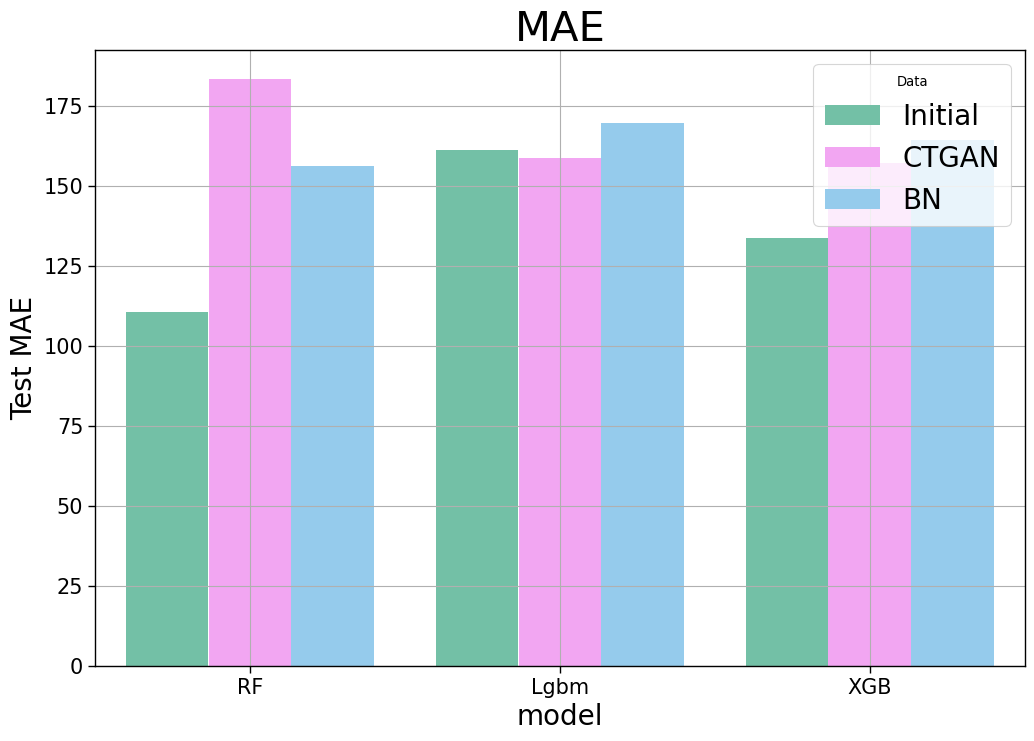

In [255]:
df = pd.concat([df_rfreg, df_lgbmreg, df_xgbreg])
df.index.rename('Data', inplace=True)
df.reset_index(inplace=True)

pastel_colors = ['#66CDAA', '#FF99FF', '#87CEFA']

fig = plt.figure(figsize=(12, 8))
sns.barplot(x='model', y='Test MAE', hue='Data', data=df, palette=pastel_colors)
plt.title('MAE')
plt.grid()
plt.show()